In [ ]:
! pip install kaggle
! mkdir ~/.kaggle
! cp kaggle.json ~/.kaggle/
! chmod 600 ~/.kaggle/kaggle.json


cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
!kaggle datasets download -d emmarex/plantdisease

!unzip -q plantdisease.zip -d ./plant_data && rm plantdisease.zip


Dataset URL: https://www.kaggle.com/datasets/emmarex/plantdisease
License(s): unknown
100% 658M/658M [00:08<00:00, 82.1MB/s]



In [ ]:
import shutil
import os

path_to_delete = "/content/plant_data/plantvillage"

if os.path.exists(path_to_delete):
    shutil.rmtree(path_to_delete)
    print(f"BAŞARILI: {path_to_delete} klasörü ve içindekiler silindi.")
else:
    print("HATA: Klasör bulunamadı, muhtemelen zaten silindi.")

print("Kalan klasörler:", os.listdir("/content/plant_data"))


BAŞARILI: /content/plant_data/plantvillage klasörü ve içindekiler silindi.
Kalan klasörler: ['PlantVillage']


In [ ]:
import os
import shutil

base_path = '/content/plant_data/PlantVillage'

all_folders = os.listdir(base_path)

deleted_count = 0
kept_count = 0

print("Temizlik işlemi başlatılıyor...\n")

for folder_name in all_folders:
    folder_path = os.path.join(base_path, folder_name)

    if os.path.isdir(folder_path):
        if 'Tomato' not in folder_name:
            shutil.rmtree(folder_path)
            print(f"Silindi: {folder_name}")
            deleted_count += 1
        else:
            print(f"Tutuldu: {folder_name}")
            kept_count += 1

print("-" * 30)
print(f"İşlem Tamamlandı!")
print(f"Silinen Klasör Sayısı: {deleted_count}")
print(f"Kalan Domates Klasörü Sayısı: {kept_count}")


Temizlik işlemi başlatılıyor...

Tutuldu: Tomato_Spider_mites_Two_spotted_spider_mite
Tutuldu: Tomato_Late_blight
Tutuldu: Tomato__Tomato_mosaic_virus
Tutuldu: Tomato__Target_Spot
Tutuldu: Tomato_Bacterial_spot
Tutuldu: Tomato__Tomato_YellowLeaf__Curl_Virus
Tutuldu: Tomato_Leaf_Mold
Silindi: Pepper__bell___Bacterial_spot
Silindi: Potato___Late_blight
Silindi: Pepper__bell___healthy
Silindi: Potato___healthy
Silindi: Potato___Early_blight
Tutuldu: Tomato_Septoria_leaf_spot
Tutuldu: Tomato_healthy
Tutuldu: Tomato_Early_blight
------------------------------
İşlem Tamamlandı!
Silinen Klasör Sayısı: 5
Kalan Domates Klasörü Sayısı: 10


Toplam Domates Sınıfı: 10
Toplam İşlenecek Görsel Sayısı: 16011

                               Hastalık Sınıfı  Görsel Sayısı
0                        Tomato_Bacterial_spot           2127
1                          Tomato_Early_blight           1000
2                           Tomato_Late_blight           1909
3                             Tomato_Leaf_Mold            952
4                    Tomato_Septoria_leaf_spot           1771
5  Tomato_Spider_mites_Two_spotted_spider_mite           1676
6                          Tomato__Target_Spot           1404
7        Tomato__Tomato_YellowLeaf__Curl_Virus           3208
8                  Tomato__Tomato_mosaic_virus            373
9                               Tomato_healthy           1591


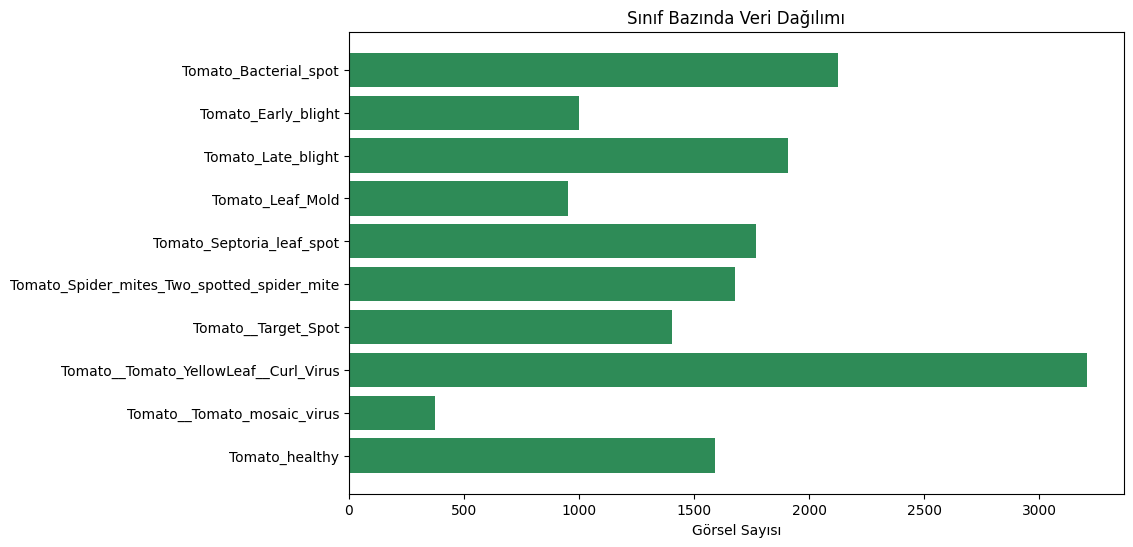

In [ ]:
import pandas as pd
from pathlib import Path

dataset_root = Path("/content/plant_data/PlantVillage")

data = {}
valid_extensions = {'.jpg', '.jpeg', '.png', '.JPG', '.PNG'}

for file_path in dataset_root.rglob('*'):
    if file_path.is_file() and file_path.suffix in valid_extensions:
        class_name = file_path.parent.name

        if class_name.lower() not in ["plantvillage", "color", "grayscale", "segmented"]:
            data[class_name] = data.get(class_name, 0) + 1

df = pd.DataFrame(list(data.items()), columns=["Hastalık Sınıfı", "Görsel Sayısı"])

df = df.sort_values("Hastalık Sınıfı").reset_index(drop=True)

print(f"Toplam Domates Sınıfı: {len(df)}")
print(f"Toplam İşlenecek Görsel Sayısı: {df['Görsel Sayısı'].sum()}\n")
print(df.to_string())

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.barh(df["Hastalık Sınıfı"], df["Görsel Sayısı"], color='seagreen')
plt.xlabel("Görsel Sayısı")
plt.title("Sınıf Bazında Veri Dağılımı")
plt.gca().invert_yaxis()
plt.show()


sss

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.7, 1.3],
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)


In [ ]:
import os
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

base_path = "/content/plant_data/PlantVillage"
target_count = 1500

print("Veri Çoğaltma İşlemi Başlıyor...")

for class_name in os.listdir(base_path):
    class_dir = os.path.join(base_path, class_name)
    if not os.path.isdir(class_dir) or class_name.lower() in ["plantvillage", "color", "grayscale", "segmented"]:
        continue

    current_files = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.jfif'))]
    current_count = len(current_files)

    if current_count < target_count:
        print(f"\n{class_name}: {current_count} görsel bulundu. {target_count}'e tamamlanıyor...")

        n_to_generate = target_count - current_count
        i = 0

        while i < n_to_generate:
            ref_img_name = np.random.choice(current_files)
            ref_img_path = os.path.join(class_dir, ref_img_name)

            img = load_img(ref_img_path)
            x = img_to_array(img)
            x = x.reshape((1,) + x.shape)

            for batch in train_datagen.flow(x, batch_size=1,
                                            save_to_dir=class_dir,
                                            save_prefix='aug',
                                            save_format='jpg'):
                i += 1
                if i >= n_to_generate:
                    break
        print(f"-> Başarılı: {class_name} artık {target_count} görsele sahip.")
    else:
        print(f"{class_name}: Zaten {current_count} görsele sahip, dokunulmadı.")

print("\n[TAMAMLANDI] Tüm azınlık sınıflar 1500'e eşitlendi.")


Veri Çoğaltma İşlemi Başlıyor...
Tomato_Spider_mites_Two_spotted_spider_mite: Zaten 1676 görsele sahip, dokunulmadı.
Tomato_Late_blight: Zaten 1909 görsele sahip, dokunulmadı.

Tomato__Tomato_mosaic_virus: 373 görsel bulundu. 1500'e tamamlanıyor...
-> Başarılı: Tomato__Tomato_mosaic_virus artık 1500 görsele sahip.

Tomato__Target_Spot: 1404 görsel bulundu. 1500'e tamamlanıyor...
-> Başarılı: Tomato__Target_Spot artık 1500 görsele sahip.
Tomato_Bacterial_spot: Zaten 2127 görsele sahip, dokunulmadı.
Tomato__Tomato_YellowLeaf__Curl_Virus: Zaten 3208 görsele sahip, dokunulmadı.

Tomato_Leaf_Mold: 952 görsel bulundu. 1500'e tamamlanıyor...
-> Başarılı: Tomato_Leaf_Mold artık 1500 görsele sahip.
Tomato_Septoria_leaf_spot: Zaten 1771 görsele sahip, dokunulmadı.
Tomato_healthy: Zaten 1591 görsele sahip, dokunulmadı.

Tomato_Early_blight: 1000 görsel bulundu. 1500'e tamamlanıyor...
-> Başarılı: Tomato_Early_blight artık 1500 görsele sahip.

[TAMAMLANDI] Tüm azınlık sınıflar 1500'e eşitlendi.


Toplam Domates Sınıfı: 10
Toplam İşlenecek Görsel Sayısı: 18184

                               Hastalık Sınıfı  Görsel Sayısı
0                        Tomato_Bacterial_spot           2127
1                          Tomato_Early_blight           1489
2                           Tomato_Late_blight           1909
3                             Tomato_Leaf_Mold           1484
4                    Tomato_Septoria_leaf_spot           1771
5  Tomato_Spider_mites_Two_spotted_spider_mite           1676
6                          Tomato__Target_Spot           1499
7        Tomato__Tomato_YellowLeaf__Curl_Virus           3208
8                  Tomato__Tomato_mosaic_virus           1430
9                               Tomato_healthy           1591


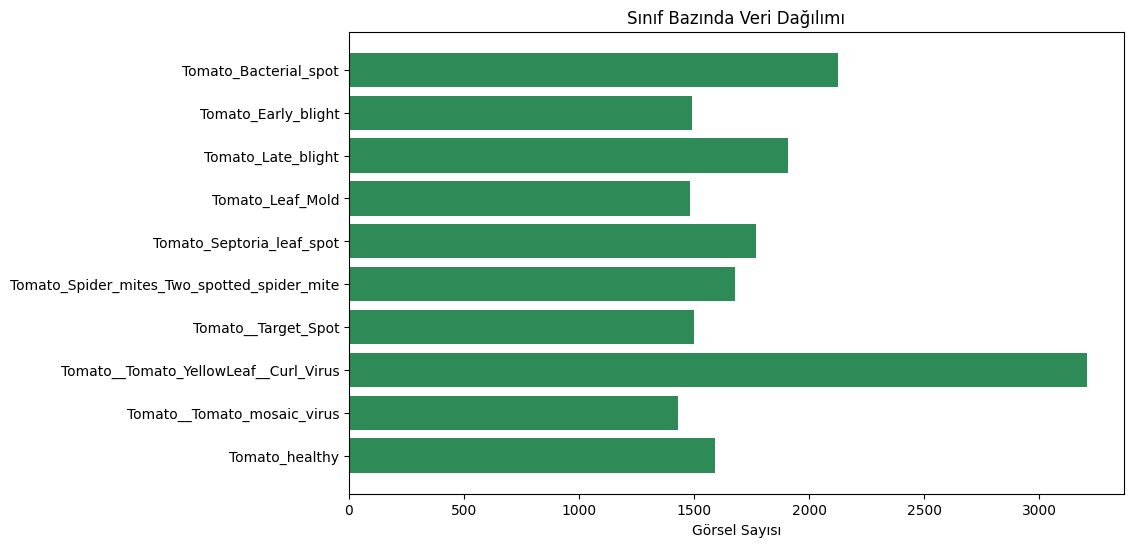

In [ ]:
import pandas as pd
from pathlib import Path

dataset_root = Path("/content/plant_data/PlantVillage")

data = {}
valid_extensions = {'.jpg', '.jpeg', '.png', '.JPG', '.PNG'}

for file_path in dataset_root.rglob('*'):
    if file_path.is_file() and file_path.suffix in valid_extensions:
        class_name = file_path.parent.name

        if class_name.lower() not in ["plantvillage", "color", "grayscale", "segmented"]:
            data[class_name] = data.get(class_name, 0) + 1

df = pd.DataFrame(list(data.items()), columns=["Hastalık Sınıfı", "Görsel Sayısı"])

df = df.sort_values("Hastalık Sınıfı").reset_index(drop=True)

print(f"Toplam Domates Sınıfı: {len(df)}")
print(f"Toplam İşlenecek Görsel Sayısı: {df['Görsel Sayısı'].sum()}\n")
print(df.to_string())

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.barh(df["Hastalık Sınıfı"], df["Görsel Sayısı"], color='seagreen')
plt.xlabel("Görsel Sayısı")
plt.title("Sınıf Bazında Veri Dağılımı")
plt.gca().invert_yaxis()
plt.show()


sss

In [ ]:
import os
import numpy as np
import cv2
from skimage.feature import local_binary_pattern, hog
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import ndimage
from pathlib import Path

DATASET_ROOT = "/content/plant_data/PlantVillage"
OUTPUT_DIR   = "/content/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMG_SIZE       = 256
MEDIAN_K       = 3
MORPH_K        = 5
MIN_AREA_RATIO = 0.05

MORPH_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (MORPH_K, MORPH_K))

np.random.seed(42)

print("Kütüphaneler ve hiperparametreler başarıyla entegre edildi.")


Kütüphaneler ve hiperparametreler başarıyla entegre edildi.


In [ ]:
import os

def build_index(root):
    index = []
    label_map = {}

    clases = [d for d in sorted(os.listdir(root)) if os.path.isdir(os.path.join(root, d))]

    for label_id, class_name in enumerate(clases):
        class_dir = os.path.join(root, class_name)
        label_map[label_id] = class_name

        for fname in os.listdir(class_dir):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                index.append({
                    "path"      : os.path.join(class_dir, fname),
                    "label_id"  : label_id,
                    "class_name": class_name
                })

    return index, label_map

ruta_correcta = None

for root_dir, dirs, files in os.walk(DATASET_ROOT):
    if not dirs:
        continue

    is_class_root = False
    for d in dirs:
        test_dir = os.path.join(root_dir, d)
        try:
            if any(f.lower().endswith(('.jpg', '.jpeg', '.png')) for f in os.listdir(test_dir)):
                is_class_root = True
                break
        except:
            continue

    if is_class_root:
        ruta_correcta = root_dir
        break

if ruta_correcta:
    print(f"Directorio base encontrado: {ruta_correcta}\n")

    index, label_map = build_index(ruta_correcta)

    print(f"Total imágenes: {len(index)}")
    print(f"Total clases  : {len(label_map)}\n")

    print(f"{'ID':>3}  {'Clase':<45}  {'N':>5}")
    print("-" * 58)

    counts = {}
    for x in index:
        counts[x["label_id"]] = counts.get(x["label_id"], 0) + 1

    for lid, cname in label_map.items():
        n = counts.get(lid, 0)
        print(f"{lid:>3}  {cname:<45}  {n:>5}")
else:
    print(f"Error: No se encontró estructura de clases de imágenes en {DATASET_ROOT}")


Directorio base encontrado: /content/plant_data/PlantVillage

Total imágenes: 18184
Total clases  : 10

 ID  Clase                                              N
----------------------------------------------------------
  0  Tomato_Bacterial_spot                           2127
  1  Tomato_Early_blight                             1489
  2  Tomato_Late_blight                              1909
  3  Tomato_Leaf_Mold                                1484
  4  Tomato_Septoria_leaf_spot                       1771
  5  Tomato_Spider_mites_Two_spotted_spider_mite     1676
  6  Tomato__Target_Spot                             1499
  7  Tomato__Tomato_YellowLeaf__Curl_Virus           3208
  8  Tomato__Tomato_mosaic_virus                     1430
  9  Tomato_healthy                                  1591


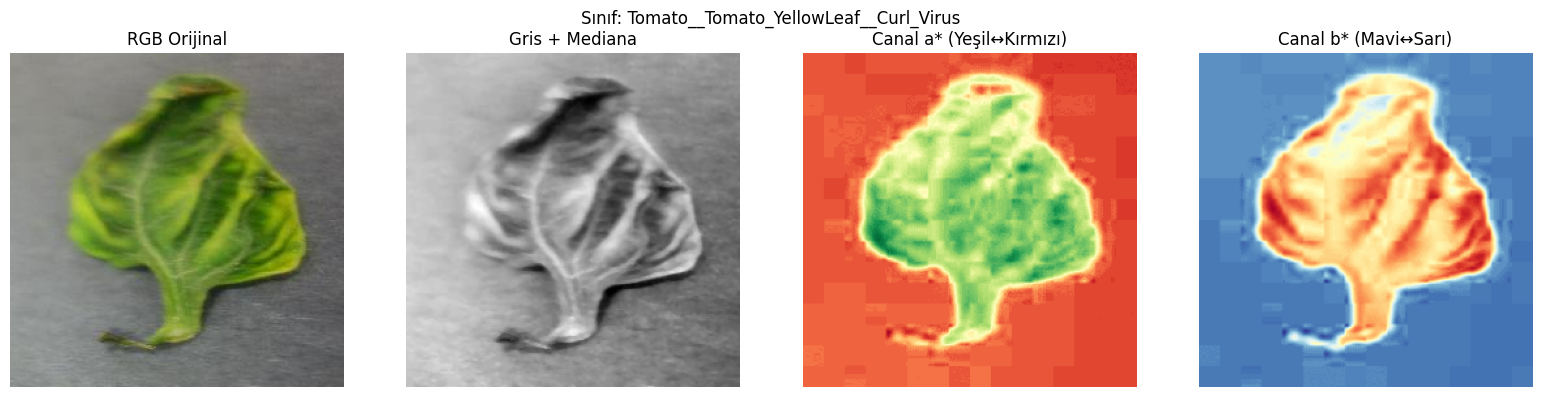

In [ ]:
def load_and_preprocess(path):
    bgr   = cv2.imread(path)
    if bgr is None:
        raise ValueError(f"Görsel yüklenemedi: {path}")

    rgb   = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    rgb   = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

    gray  = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    gray  = cv2.medianBlur(gray, MEDIAN_K)

    lab   = cv2.cvtColor(rgb, cv2.COLOR_RGB2Lab)

    return rgb, gray, lab

import random
sample = random.choice(index)
rgb, gray, lab = load_and_preprocess(sample["path"])

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(rgb);              axes[0].set_title("RGB Orijinal")
axes[1].imshow(gray, cmap="gray"); axes[1].set_title("Gris + Mediana")
axes[2].imshow(lab[:,:,1], cmap="RdYlGn_r"); axes[2].set_title("Canal a* (Yeşil↔Kırmızı)")
axes[3].imshow(lab[:,:,2], cmap="RdYlBu_r"); axes[3].set_title("Canal b* (Mavi↔Sarı)")

for ax in axes: ax.axis("off")
plt.suptitle(f"Sınıf: {sample['class_name']}", fontsize=12)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIR}/preproc_sample.png", dpi=120)
plt.show()


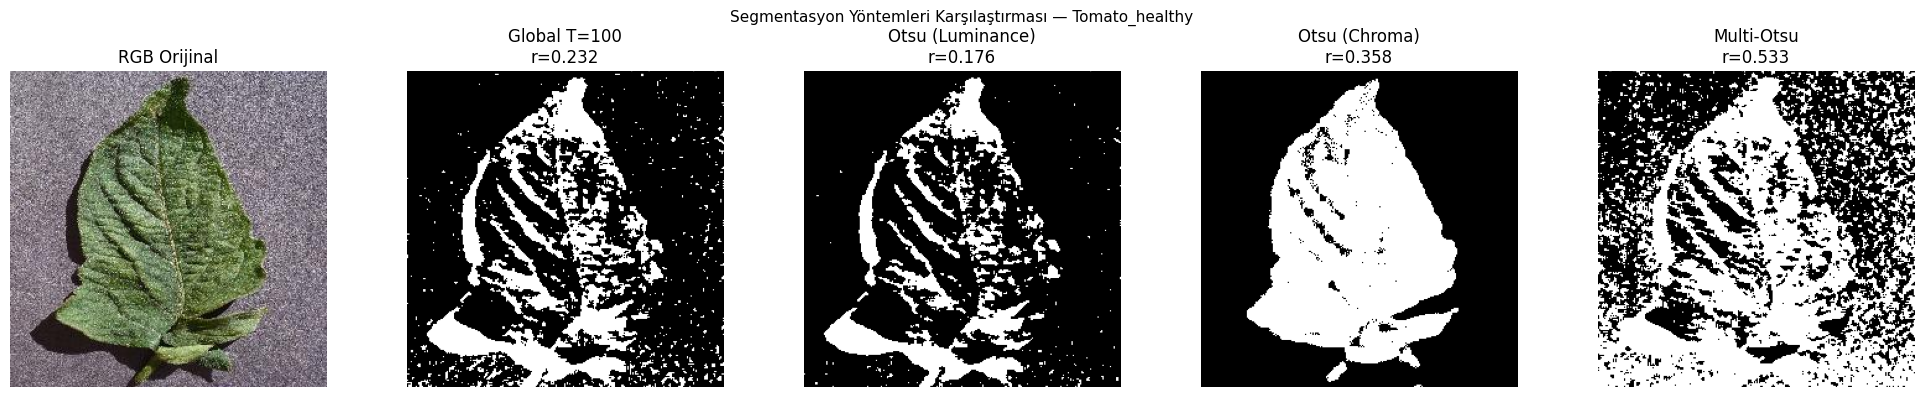

In [ ]:
from skimage.filters import threshold_multiotsu

def compute_chroma(lab):
    a = lab[:, :, 1].astype(np.float32) - 128.0
    b = lab[:, :, 2].astype(np.float32) - 128.0
    return np.clip(np.sqrt(a**2 + b**2), 0, 255).astype(np.uint8)

def area_ratio(mask):
    return float(np.count_nonzero(mask)) / (mask.shape[0] * mask.shape[1])

def segment_global(gray, threshold=100):
    _, mask = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY_INV)
    return mask

def segment_otsu_luminance(gray):
    _, mask = cv2.threshold(gray, 0, 255,
                            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return mask

def segment_otsu_chroma(lab):
    chroma = compute_chroma(lab)
    _, mask = cv2.threshold(chroma, 0, 255,
                            cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return mask

def segment_multiotsu(gray):
    try:
        thresholds = threshold_multiotsu(gray, classes=3)
        regions = np.digitize(gray, bins=thresholds)
        return np.where(regions <= 1, 255, 0).astype(np.uint8)
    except ValueError:
        return segment_otsu_luminance(gray)

def compare_segmentation_methods(item, out_dir):
    rgb, gray, lab = load_and_preprocess(item["path"])
    mask_glob   = segment_global(gray)
    mask_otsu_L = segment_otsu_luminance(gray)
    mask_otsu_C = segment_otsu_chroma(lab)
    mask_multi  = segment_multiotsu(gray)

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    axes[0].imshow(rgb);                        axes[0].set_title("RGB Orijinal")
    axes[1].imshow(mask_glob,    cmap="gray");  axes[1].set_title(f"Global T=100\nr={area_ratio(mask_glob):.3f}")
    axes[2].imshow(mask_otsu_L,  cmap="gray");  axes[2].set_title(f"Otsu (Luminance)\nr={area_ratio(mask_otsu_L):.3f}")
    axes[3].imshow(mask_otsu_C,  cmap="gray");  axes[3].set_title(f"Otsu (Chroma)\nr={area_ratio(mask_otsu_C):.3f}")
    axes[4].imshow(mask_multi,   cmap="gray");  axes[4].set_title(f"Multi-Otsu\nr={area_ratio(mask_multi):.3f}")

    for ax in axes: ax.axis("off")
    plt.suptitle(f"Segmentasyon Yöntemleri Karşılaştırması — {item['class_name']}", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{out_dir}/segmentation_methods_{item['class_name'][:30]}.png", dpi=120)
    plt.show()

sample_item = random.choice(index)
compare_segmentation_methods(sample_item, OUTPUT_DIR)


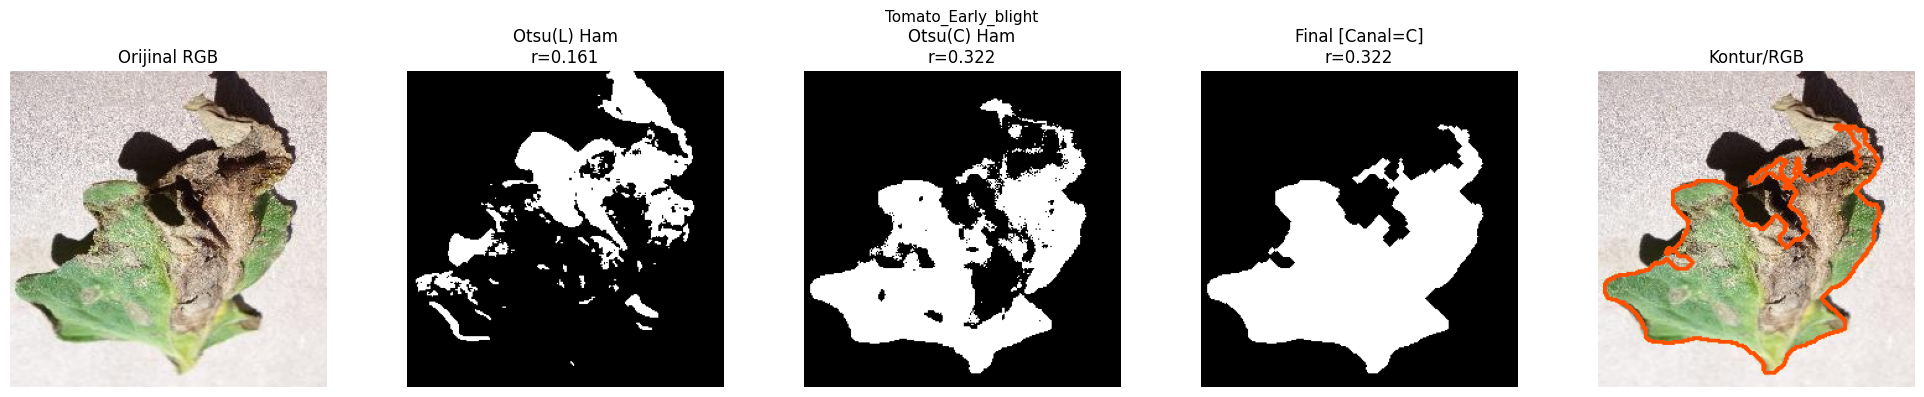

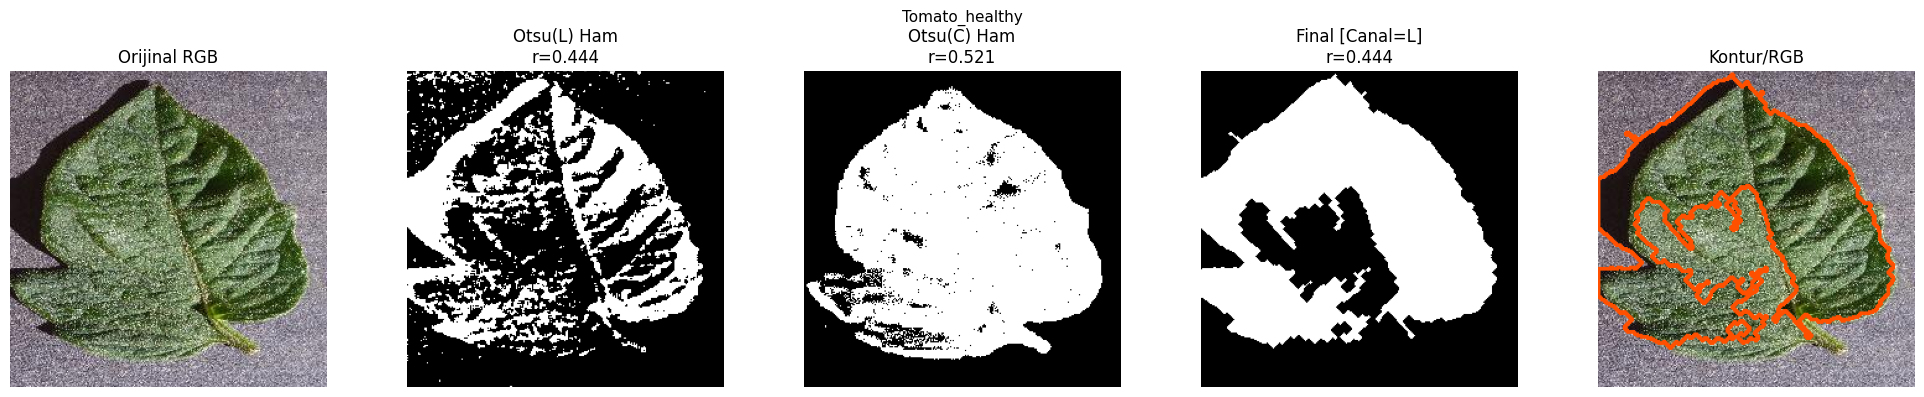

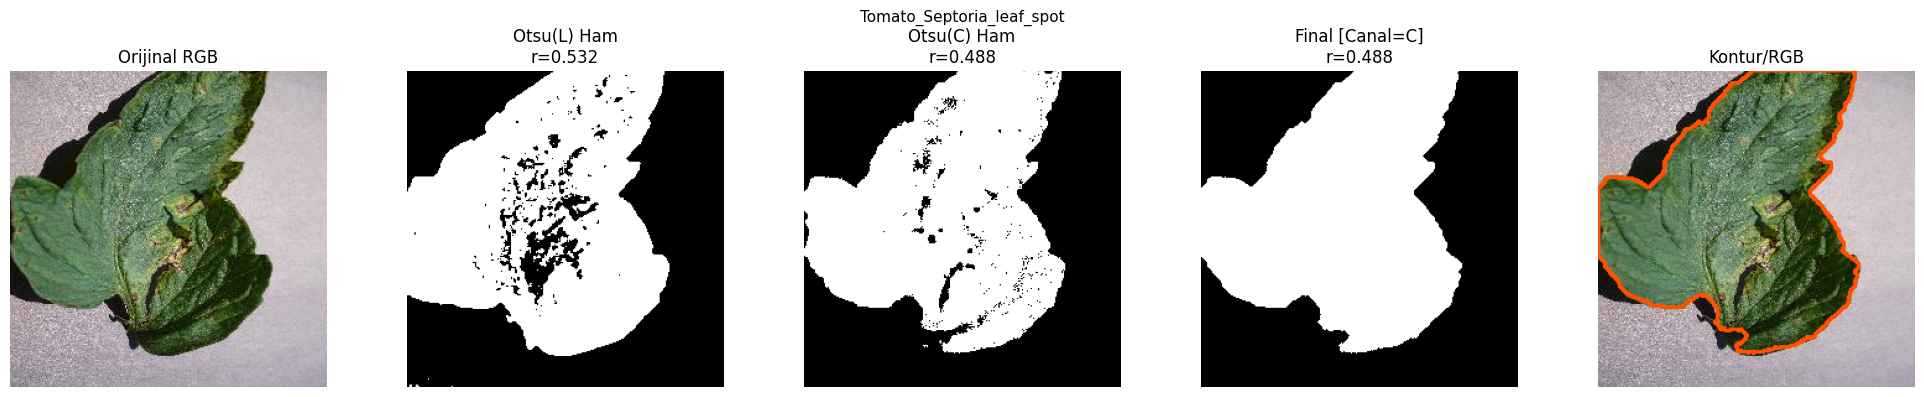

In [ ]:
from scipy.ndimage import binary_fill_holes as _bfh

MORPH_OPEN_K   = 3
MORPH_CLOSE_K  = 5
RATIO_VALID_LO = 0.10
RATIO_VALID_HI = 0.90
RATIO_TARGET   = 0.38

def _fill_holes_safe(mask):
    padded = np.pad(mask.astype(bool), pad_width=1, constant_values=False)
    return _bfh(padded)[1:-1, 1:-1].astype(np.uint8) * 255

def _largest_component(mask):
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if n < 2:
        return mask
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return np.where(labels == largest, 255, 0).astype(np.uint8)

def refine_mask(raw_mask):
    k_open  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (MORPH_OPEN_K, MORPH_OPEN_K))
    k_close = cv2.getStructuringElement(cv2.MORPH_CLOSE, (MORPH_CLOSE_K, MORPH_CLOSE_K))
    opened  = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN,  k_open,  iterations=1)
    closed  = cv2.morphologyEx(opened,   cv2.MORPH_CLOSE, k_close, iterations=2)
    filled  = _fill_holes_safe(closed)
    return _largest_component(filled)

def build_final_mask(gray, lab):
    raw_L   = segment_otsu_luminance(gray)
    raw_C   = segment_otsu_chroma(lab)
    final_L = refine_mask(raw_L)
    final_C = refine_mask(raw_C)

    r_L     = area_ratio(final_L)
    r_C     = area_ratio(final_C)

    L_ok = RATIO_VALID_LO <= r_L <= RATIO_VALID_HI
    C_ok = RATIO_VALID_LO <= r_C <= RATIO_VALID_HI

    if L_ok and C_ok:
        if abs(r_L - RATIO_TARGET) <= abs(r_C - RATIO_TARGET):
            return final_L, "L", r_L, r_C
        return final_C, "C", r_L, r_C
    if L_ok: return final_L, "L", r_L, r_C
    if C_ok: return final_C, "C", r_L, r_C

    best = final_L if r_L >= r_C else final_C
    ch   = "L_fallback" if r_L >= r_C else "C_fallback"
    return best, ch, r_L, r_C

def verify_final_segmentation(item, out_dir):
    rgb, gray, lab = load_and_preprocess(item["path"])
    raw_L = segment_otsu_luminance(gray)
    raw_C = segment_otsu_chroma(lab)
    final, channel, r_L, r_C = build_final_mask(gray, lab)

    overlay = rgb.copy()
    contours, _ = cv2.findContours(final, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(overlay, contours, -1, (255, 80, 0), 2)

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    axes[0].imshow(rgb);                      axes[0].set_title("Orijinal RGB")
    axes[1].imshow(raw_L,   cmap="gray");     axes[1].set_title(f"Otsu(L) Ham\nr={r_L:.3f}")
    axes[2].imshow(raw_C,   cmap="gray");     axes[2].set_title(f"Otsu(C) Ham\nr={r_C:.3f}")
    axes[3].imshow(final,   cmap="gray");     axes[3].set_title(f"Final [Canal={channel}]\nr={area_ratio(final):.3f}")
    axes[4].imshow(overlay);                  axes[4].set_title("Kontur/RGB")
    for ax in axes: ax.axis("off")
    plt.suptitle(item["class_name"], fontsize=11)
    plt.tight_layout()
    plt.show()

for cname in ["Tomato_Early_blight", "Tomato_healthy", "Tomato_Septoria_leaf_spot"]:
    hits = [x for x in index if cname in x["class_name"]]
    if hits:
        verify_final_segmentation(hits[0], OUTPUT_DIR)


/tmp/ipykernel_963/3183664718.py:38: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([ratios_raw, ratios_final],


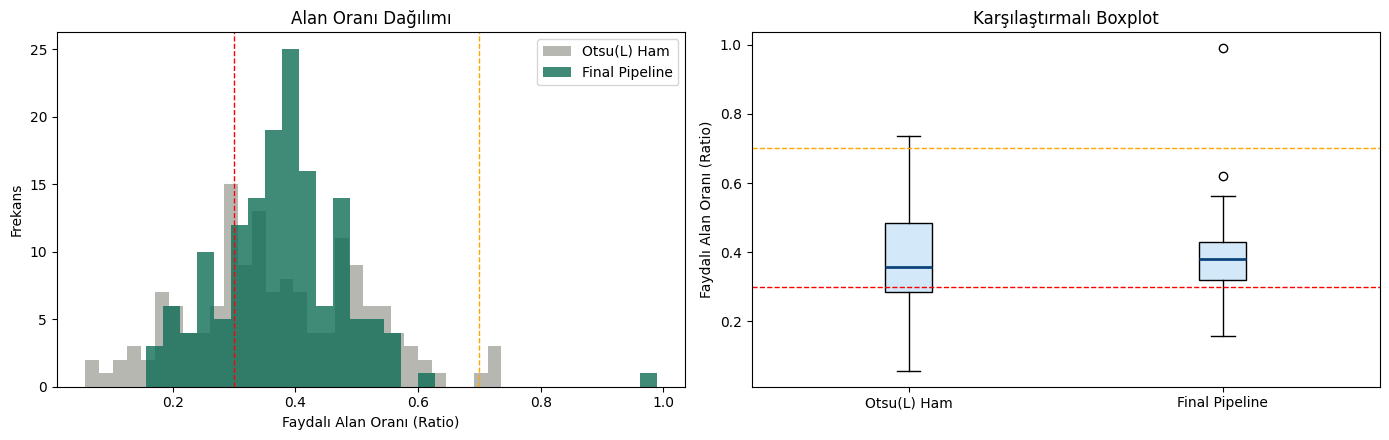


── Otsu(L) Ham      Ortalama=0.372   Standart Sapma=0.141
── Final Pipeline   Ortalama=0.379  Standart Sapma=0.105
── Seçilen Kanallar  {'L': 57, 'C': 92, 'C_fallback': 1}
── Beklenen Aralıkta [0.20, 0.70]: 143/150 (%95.3)


In [ ]:
def validate_segmentation(index, n_sample=150, out_dir=OUTPUT_DIR):
    rng = np.random.default_rng(42)
    idx_sample = rng.choice(len(index), size=min(n_sample, len(index)), replace=False)

    ratios_raw, ratios_final, channels = [], [], []

    for i in idx_sample:
        try:
            rgb, gray, lab = load_and_preprocess(index[i]["path"])
            raw_L                      = segment_otsu_luminance(gray)
            final, channel, _, _       = build_final_mask(gray, lab)
            ratios_raw.append(area_ratio(raw_L))
            ratios_final.append(area_ratio(final))
            channels.append(channel)
        except Exception as e:
            continue

    ratios_raw   = np.array(ratios_raw)
    ratios_final = np.array(ratios_final)

    from collections import Counter
    channel_counts = Counter(channels)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    axes[0].hist(ratios_raw,   bins=30, color="#888780", alpha=0.6, label="Otsu(L) Ham")
    axes[0].hist(ratios_final, bins=30, color="#0F6E56", alpha=0.8, label="Final Pipeline")
    axes[0].axvline(0.30, color="red",    linestyle="--", linewidth=1)
    axes[0].axvline(0.70, color="orange", linestyle="--", linewidth=1)
    axes[0].set_xlabel("Faydalı Alan Oranı (Ratio)")
    axes[0].set_ylabel("Frekans")
    axes[0].legend()
    axes[0].set_title("Alan Oranı Dağılımı")

    axes[1].boxplot([ratios_raw, ratios_final],
                    labels=["Otsu(L) Ham", "Final Pipeline"],
                    patch_artist=True,
                    boxprops=dict(facecolor="#D3E8F8"),
                    medianprops=dict(color="#0C447C", linewidth=2))
    axes[1].axhline(0.30, color="red",    linestyle="--", linewidth=1)
    axes[1].axhline(0.70, color="orange", linestyle="--", linewidth=1)
    axes[1].set_ylabel("Faydalı Alan Oranı (Ratio)")
    axes[1].set_title("Karşılaştırmalı Boxplot")

    plt.tight_layout()
    plt.savefig(f"{out_dir}/area_ratio_validation.png", dpi=120)
    plt.show()

    print(f"\n── Otsu(L) Ham      Ortalama={ratios_raw.mean():.3f}   Standart Sapma={ratios_raw.std():.3f}")
    print(f"── Final Pipeline   Ortalama={ratios_final.mean():.3f}  Standart Sapma={ratios_final.std():.3f}")
    print(f"── Seçilen Kanallar  {dict(channel_counts)}")

    n_valid = int(np.sum((ratios_final >= 0.20) & (ratios_final <= 0.70)))
    print(f"── Beklenen Aralıkta [0.20, 0.70]: {n_valid}/{len(ratios_final)} "
          f"(%{100*n_valid/len(ratios_final):.1f})")

validate_segmentation(index, n_sample=150)


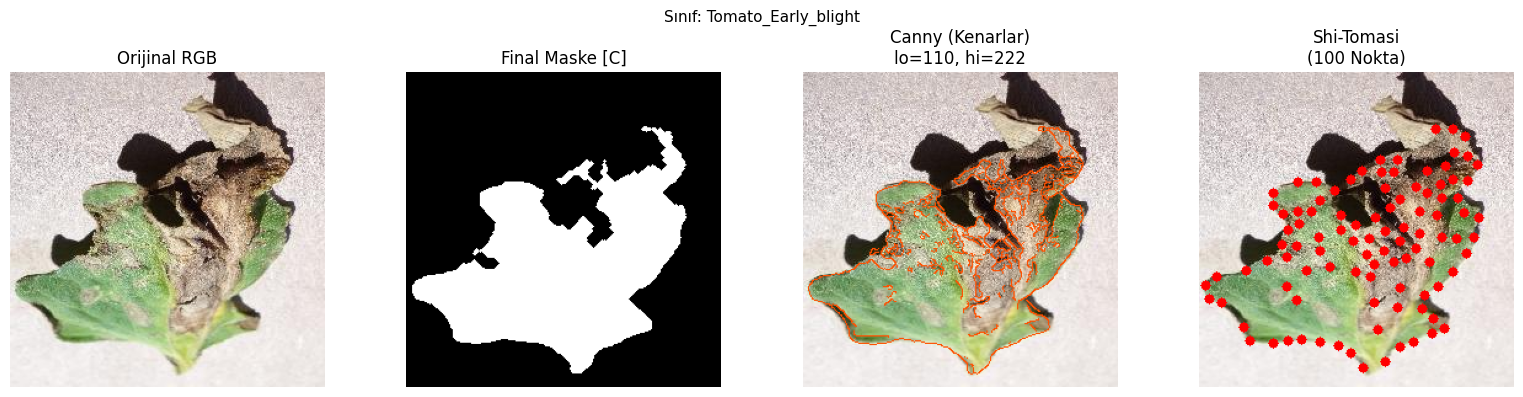

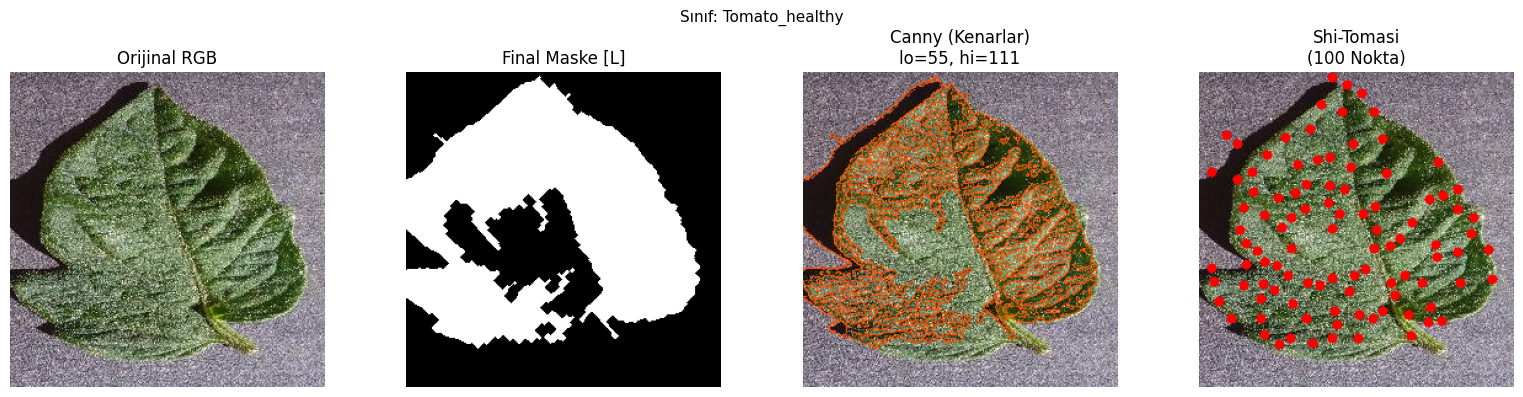

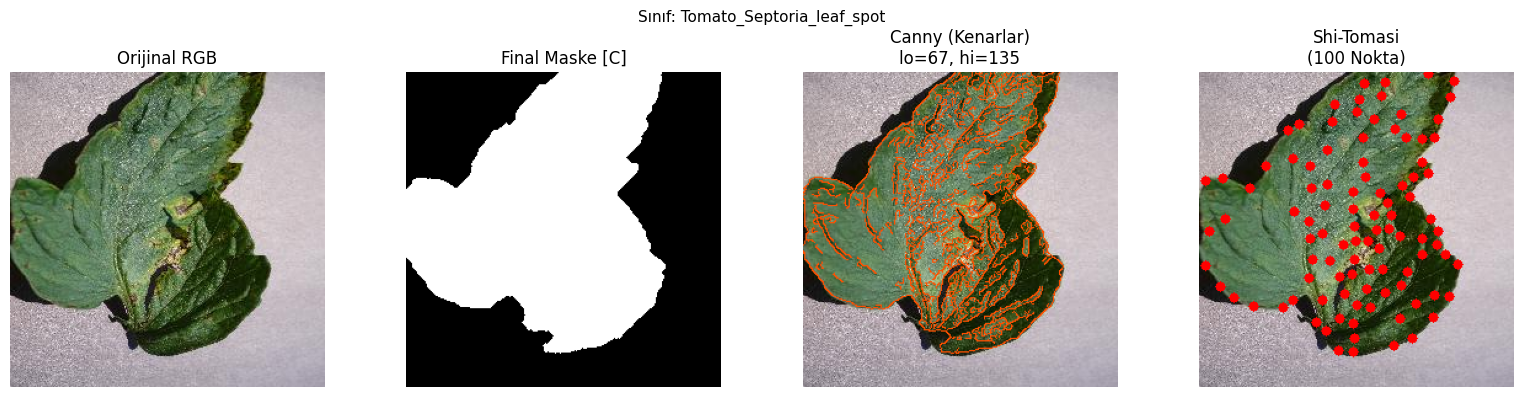

In [ ]:
def detect_edges(gray, mask):
    masked = cv2.bitwise_and(gray, gray, mask=mask)
    valid = masked[mask > 0]

    if valid.size == 0:
        return np.zeros_like(gray), 0, 0

    med = float(np.median(valid))
    lo  = int(max(0,   0.66 * med))
    hi  = int(min(255, 1.33 * med))

    edges = cv2.Canny(masked, lo, hi)
    return edges, lo, hi

def detect_corners(gray, mask, max_corners=100):
    masked = cv2.bitwise_and(gray, gray, mask=mask)
    corners = cv2.goodFeaturesToTrack(
        masked,
        maxCorners=max_corners,
        qualityLevel=0.01,
        minDistance=10,
        mask=mask,
        useHarrisDetector=False
    )
    return corners if corners is not None else np.zeros((0, 1, 2), dtype=np.float32)

def visualize_edges_corners(item, out_dir):
    rgb, gray, lab = load_and_preprocess(item["path"])
    mask, channel, _, _ = build_final_mask(gray, lab)
    edges, lo, hi       = detect_edges(gray, mask)
    corners             = detect_corners(gray, mask)

    overlay_edges = rgb.copy()
    overlay_edges[edges > 0] = (255, 80, 0)

    overlay_corners = rgb.copy()
    for pt in corners.reshape(-1, 2):
        cv2.circle(overlay_corners, (int(pt[0]), int(pt[1])), 4, (255, 0, 0), -1)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(rgb);                axes[0].set_title("Orijinal RGB")
    axes[1].imshow(mask, cmap="gray");  axes[1].set_title(f"Final Maske [{channel}]")
    axes[2].imshow(overlay_edges);      axes[2].set_title(f"Canny (Kenarlar)\nlo={lo}, hi={hi}")
    axes[3].imshow(overlay_corners);    axes[3].set_title(f"Shi-Tomasi\n({len(corners)} Nokta)")

    for ax in axes: ax.axis("off")
    plt.suptitle(f"Sınıf: {item['class_name']}", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{out_dir}/edges_corners_{item['class_name'][:30]}.png", dpi=120)
    plt.show()

for cname in ["Tomato_Early_blight", "Tomato_healthy", "Tomato_Septoria_leaf_spot"]:
    hits = [x for x in index if cname in x["class_name"]]
    if hits:
        visualize_edges_corners(hits[0], OUTPUT_DIR)


In [ ]:
from collections import Counter
from tqdm import tqdm

MIN_AREA_RATIO = 0.05
MAX_AREA_RATIO = 0.95

def serialize_all(index, out_dir):
    masks_dir = os.path.join(out_dir, "masks")
    os.makedirs(masks_dir, exist_ok=True)

    paths, labels, mask_paths       = [], [], []
    area_ratios_list, channels_used = [], []
    skipped_low, skipped_high       = 0, 0

    for i, item in enumerate(tqdm(index, desc="Maskeler Oluşturuluyor")):
        try:
            _, gray_i, lab_i = load_and_preprocess(item["path"])
            final_i, ch_i, _, _ = build_final_mask(gray_i, lab_i)
            r = area_ratio(final_i)

            if r < MIN_AREA_RATIO:
                skipped_low += 1
                continue
            if r > MAX_AREA_RATIO:
                skipped_high += 1
                continue

            fname = f"{i:05d}.npy"
            np.save(os.path.join(masks_dir, fname), final_i)

            paths.append(item["path"])
            labels.append(item["label_id"])
            mask_paths.append(os.path.join(masks_dir, fname))
            area_ratios_list.append(r)
            channels_used.append(ch_i)
        except Exception as e:
            continue

    paths         = np.array(paths)
    labels        = np.array(labels, dtype=np.int32)
    mask_paths    = np.array(mask_paths)
    area_ratios_a = np.array(area_ratios_list, dtype=np.float32)
    channels_a    = np.array(channels_used)
    ch_counts     = Counter(channels_used)

    contract = {
        "paths"           : paths,
        "labels"          : labels,
        "mask_paths"      : mask_paths,
        "area_ratios"     : area_ratios_a,
        "channels_used"   : channels_a,
        "label_map"       : label_map,
        "img_size"        : IMG_SIZE,
        "n_classes"       : len(label_map),
        "n_kept"          : len(paths),
        "n_skipped_low"   : skipped_low,
        "n_skipped_high"  : skipped_high,
        "seg_method"      : "Otsu_L_vs_C_adaptive",
        "morph_open_k"    : MORPH_OPEN_K,
        "morph_close_k"   : MORPH_CLOSE_K,
    }

    contract_path = os.path.join(out_dir, "dataset_contract.npy")
    np.save(contract_path, contract, allow_pickle=True)

    print("\n" + "="*60)
    print(f"Toplam Görsel Sayısı     : {len(index)}")
    print(f"Başarıyla İşlenen        : {len(paths)}")
    print(f"Elenen (Çok Küçük Alan)  : {skipped_low}")
    print(f"Elenen (Çok Büyük Alan)  : {skipped_high}")
    print(f"Ortalama Yaprak Alanı    : {area_ratios_a.mean():.3f} ± {area_ratios_a.std():.3f}")
    print(f"Kanal Dağılımı           : {dict(ch_counts)}")
    print(f"Veri Sözleşmesi Kaydedildi: {contract_path}")
    print("="*60)

    return contract

contract = serialize_all(index, OUTPUT_DIR)


Maskeler Oluşturuluyor: 100%|██████████| 18184/18184 [03:51<00:00, 78.47it/s]


Toplam Görsel Sayısı     : 18184
Başarıyla İşlenen        : 18175
Elenen (Çok Küçük Alan)  : 0
Elenen (Çok Büyük Alan)  : 9
Ortalama Yaprak Alanı    : 0.380 ± 0.091
Kanal Dağılımı           : {'C': 11265, 'L': 6892, 'L_fallback': 12, 'C_fallback': 6}
Veri Sözleşmesi Kaydedildi: /content/outputs/dataset_contract.npy


In [ ]:
import numpy as np
import cv2
from skimage.feature import local_binary_pattern, hog
from skimage.color import rgb2lab, rgb2gray
from scipy.stats import skew

def extract_lbp_multiscale(img_rgb, mask):
    """LBP (Local Binary Pattern): Yaprak dokusundaki pürüzlülüğü ve mikro desenleri
    farklı ölçeklerde (multiscale) yakalar. Hastalık lekelerinin dokusunu tanımlar."""
    img_lab   = rgb2lab(img_rgb)
    L_channel = (img_lab[:, :, 0] / 100 * 255).clip(0, 255).astype(np.uint8)

    escalas   = [(8, 1), (16, 2), (24, 3)]
    hist_concat = []

    for P, R in escalas:
        lbp         = local_binary_pattern(L_channel, P, R, method='uniform')
        lbp_masked  = lbp[mask > 0]
        hist, _     = np.histogram(lbp_masked, bins=np.arange(0, P + 3), density=False)
        hist        = hist.astype(float)
        s           = hist.sum()
        if s > 0:
            hist /= s
        hist_concat.extend(hist)
    return np.array(hist_concat, dtype=np.float32)

def extract_hog_pyramidal(img_rgb, mask):
    """HOG (Histogram of Oriented Gradients): Yaprak üzerindeki lezyonların kenar
    yönelimlerini ve geometrik şekillerini piramidal yapıda (iki farklı çözünürlük) çıkarır."""
    img_masked       = img_rgb * np.expand_dims(mask > 0, axis=-1)
    img_gray_256     = rgb2gray(img_masked)
    img_gray_128     = cv2.resize(img_gray_256, (128, 128), interpolation=cv2.INTER_AREA)

    hog1 = hog(img_gray_256, orientations=9, pixels_per_cell=(16, 16),
               cells_per_block=(2, 2), feature_vector=True)
    hog2 = hog(img_gray_128, orientations=9, pixels_per_cell=(16, 16),
               cells_per_block=(2, 2), feature_vector=True)

    hog_cat    = np.concatenate([hog1, hog2]).astype(np.float32)
    hellinger  = np.sqrt(np.clip(hog_cat, 0, None))
    norm       = np.linalg.norm(hellinger)
    if norm > 0:
        hellinger /= norm
    return hellinger

def extract_lcs(img_rgb, mask):
    """LCS (Lesion Color Signature): Lezyon Renk İmzası.
    a* ve b* kanallarındaki renk dağılımını, nekroz (ölü doku) ve kloroz (sararma)
    oranlarını hesaplayan, senin çalışmana has biyolojik bir öznitelik vektörüdür."""
    img_lab = rgb2lab(img_rgb)
    L_m = img_lab[:, :, 0][mask > 0]
    a_m = img_lab[:, :, 1][mask > 0]
    b_m = img_lab[:, :, 2][mask > 0]

    if len(L_m) == 0:
        return np.zeros(264, dtype=np.float32)

    hist2d, _, _ = np.histogram2d(
        a_m, b_m, bins=16,
        range=[[-128, 128], [-128, 128]], density=True)
    hist2d_flat = hist2d.flatten().astype(np.float32)

    moments = np.array([
        np.mean(a_m), np.std(a_m), float(skew(a_m)),
        np.mean(b_m), np.std(b_m), float(skew(b_m))
    ], dtype=np.float32)

    ratio_necrotico = float(np.sum((a_m > 0) & (L_m < 50)) / len(L_m))
    ratio_clorotico = float(np.sum((b_m > 20) & (np.abs(a_m) < 5)) / len(a_m))

    lcs_vec = np.concatenate([hist2d_flat, moments, [ratio_necrotico, ratio_clorotico]])
    norm = np.linalg.norm(lcs_vec)
    if norm > 0:
        lcs_vec /= norm
    return lcs_vec.astype(np.float32)

print("Gelişmiş öznitelik çıkarıcılar başarıyla tanımlandı.")


Gelişmiş öznitelik çıkarıcılar başarıyla tanımlandı.


In [ ]:
import os
from tqdm.auto import tqdm
from concurrent.futures import ProcessPoolExecutor

contract_path = os.path.join(OUTPUT_DIR, "dataset_contract.npy")
_contract     = np.load(contract_path, allow_pickle=True).item()
_rutas_img  = list(_contract["paths"])
_rutas_msk  = list(_contract["mask_paths"])
_etiquetas  = _contract["labels"]

def _procesar_imagen(args):
    """
    Worker Fonksiyonu: Her bir görsel için LBP, HOG ve LCS özniteliklerini hesaplar.
    """
    img_path, mask_path, label = args
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        return None
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    try:
        mask = np.load(mask_path)
    except Exception:
        return None

    mask_bin = (mask > 0).astype(np.uint8)

    f_lbp = extract_lbp_multiscale(img_rgb, mask_bin)
    f_hog = extract_hog_pyramidal(img_rgb, mask_bin)
    f_lcs = extract_lcs(img_rgb, mask_bin)

    return (f_lbp, f_hog, f_lcs, label)

tareas = [(_rutas_img[i], _rutas_msk[i], _etiquetas[i])
          for i in range(len(_rutas_img))]

X_lbp_list, X_hog_list, X_lcs_list, y_list = [], [], [], []

with ProcessPoolExecutor(max_workers=4) as executor:
    resultados = list(tqdm(
        executor.map(_procesar_imagen, tareas),
        total=len(tareas), desc="Öznitelikler Çıkarılıyor", unit="img"
    ))

for res in resultados:
    if res is not None:
        lbp, hog_f, lcs, lbl = res
        X_lbp_list.append(lbp)
        X_hog_list.append(hog_f)
        X_lcs_list.append(lcs)
        y_list.append(lbl)

X_lbp    = np.array(X_lbp_list, dtype=np.float32)
X_hog    = np.array(X_hog_list, dtype=np.float32)
X_lcs    = np.array(X_lcs_list, dtype=np.float32)
y_labels = np.array(y_list,     dtype=np.int32)

print(f"\nLBP Matrisi : {X_lbp.shape}")
print(f"HOG Matrisi : {X_hog.shape}")
print(f"LCS Matrisi : {X_lcs.shape}")
print(f"Etiketler   : {y_labels.shape}")

np.save(os.path.join(OUTPUT_DIR, "X_lbp.npy"),    X_lbp)
np.save(os.path.join(OUTPUT_DIR, "X_hog.npy"),    X_hog)
np.save(os.path.join(OUTPUT_DIR, "X_lcs.npy"),    X_lcs)
np.save(os.path.join(OUTPUT_DIR, "y_labels.npy"), y_labels)

print("\nÖznitelik vektörleri başarıyla kaydedildi: ", OUTPUT_DIR)


Öznitelikler Çıkarılıyor:   0%|          | 0/18175 [00:00<?, ?img/s]


LBP Matrisi : (18175, 54)
HOG Matrisi : (18175, 9864)
LCS Matrisi : (18175, 264)
Etiketler   : (18175,)

Öznitelik vektörleri başarıyla kaydedildi:  /content/outputs


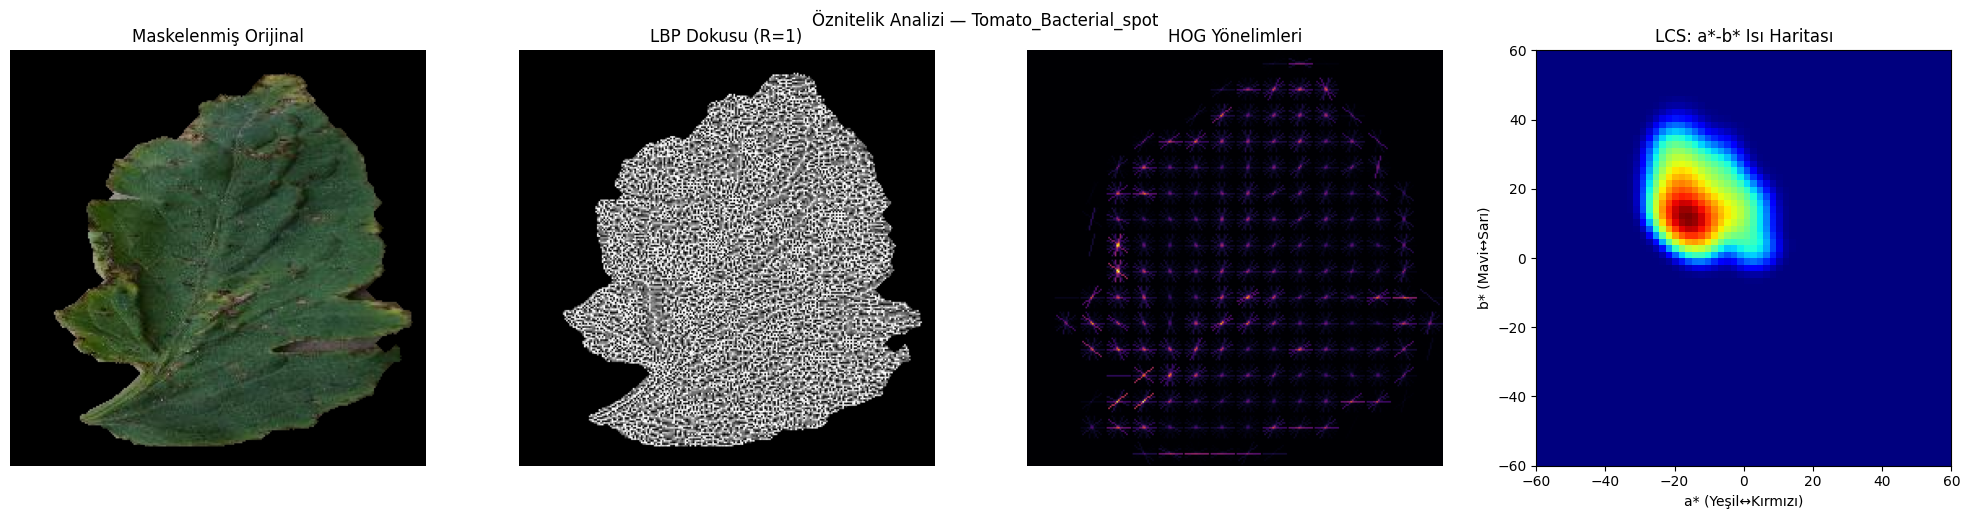

In [ ]:
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
from skimage.color import rgb2lab as _rgb2lab

idx     = 0
img_bgr = cv2.imread(_rutas_img[idx])
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
mask_b  = (np.load(_rutas_msk[idx]) > 0).astype(np.uint8)

img_lab = _rgb2lab(img_rgb)

img_masked = img_rgb.copy()
img_masked[mask_b == 0] = 0

L_u8  = (img_lab[:, :, 0] / 100 * 255).clip(0, 255).astype(np.uint8)
lbp_map = local_binary_pattern(L_u8, 8, 1, method='uniform')
lbp_map[mask_b == 0] = 0

img_gray  = rgb2gray(img_masked)
_, hog_img = hog(img_gray, orientations=9, pixels_per_cell=(16, 16),
                 cells_per_block=(2, 2), visualize=True)

a_m = img_lab[:, :, 1][mask_b > 0]
b_m = img_lab[:, :, 2][mask_b > 0]
h, _, _ = np.histogram2d(a_m, b_m, bins=64,
                          range=[[-60, 60], [-60, 60]])
h_smooth = gaussian_filter(h.T, sigma=1.5)

fig, axs = plt.subplots(1, 4, figsize=(20, 5))

axs[0].imshow(img_masked)
axs[0].set_title("Maskelenmiş Orijinal")

axs[1].imshow(lbp_map, cmap='gray')
axs[1].set_title("LBP Dokusu (R=1)")

axs[2].imshow(hog_img, cmap='inferno')
axs[2].set_title("HOG Yönelimleri")

im = axs[3].imshow(h_smooth + 1, origin='lower', extent=[-60, 60, -60, 60],
                   cmap='jet', norm=LogNorm())
axs[3].set_title("LCS: a*-b* Isı Haritası")
axs[3].set_xlabel("a* (Yeşil↔Kırmızı)")
axs[3].set_ylabel("b* (Mavi↔Sarı)")

for ax in axs[:3]:
    ax.axis('off')

try:
    curr_label_id = int(_etiquetas[idx])
    if curr_label_id in _contract['label_map']:
        class_name = _contract['label_map'][curr_label_id]
    elif str(curr_label_id) in _contract['label_map']:
        class_name = _contract['label_map'][str(curr_label_id)]
    else:
        class_name = f"ID: {curr_label_id}"
except Exception:
    class_name = "Bilinmeyen Sınıf"

plt.suptitle(f"Öznitelik Analizi — {class_name}", fontsize=12)
plt.tight_layout()

plt.savefig(os.path.join(OUTPUT_DIR, "descriptores_visualizacion.png"), dpi=120)
plt.show()


In [ ]:
import numpy as np
import os

CACHE_DIR = OUTPUT_DIR

if not os.path.exists(CACHE_DIR):
    print("Uyarı: Çıktı dizini bulunamadı, varsayılan çalışma dizinine bakılıyor.")
    CACHE_DIR = "/content/outputs/"

y_labels = np.load(os.path.join(CACHE_DIR, 'y_labels.npy'))
contract  = np.load(os.path.join(CACHE_DIR, 'dataset_contract.npy'), allow_pickle=True).item()

paths      = list(contract['paths'])
mask_paths = list(contract['mask_paths'])

N = len(y_labels)

assert len(paths) == N, f"Mismatch de rutas: {len(paths)} vs {N}"

print(f"[{CACHE_DIR}] Konumundan {N} adet etiket ve dosya yolu başarıyla yüklendi.")
print(f"Örnek Görsel Yolu : {paths[0]}")
print(f"Örnek Maske Yolu  : {mask_paths[0]}")


[/content/outputs] Konumundan 18175 adet etiket ve dosya yolu başarıyla yüklendi.
Örnek Görsel Yolu : /content/plant_data/PlantVillage/Tomato_Bacterial_spot/ac444acf-1d85-4928-9f73-947497fb6b9f___GCREC_Bact.Sp 5762.JPG
Örnek Maske Yolu  : /content/outputs/masks/00000.npy


In [ ]:
import cv2
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from tqdm.auto import tqdm
import gc

def extract_dense_sift_root(img_path: str, mask_path: str, stride: int = 6):
    """RootSIFT: SIFT deskriptörlerini L1 normalizasyonu ve karekök işlemiyle
    daha kararlı ve karşılaştırılabilir hale getirir."""
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        return None
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    try:
        mask     = np.load(mask_path)
        mask_u8  = (mask > 0).astype(np.uint8) * 255
    except Exception:
        return None

    sift = cv2.SIFT_create()
    kp, desc = sift.detectAndCompute(img_gray, mask=mask_u8)

    if desc is None or len(desc) == 0:
        return np.zeros((0, 128))

    desc /= (desc.sum(axis=1, keepdims=True) + 1e-7)
    desc  = np.sqrt(desc)
    return desc

np.random.seed(42)
N_SAMPLES_GMM = min(400, N)
sample_idx     = np.random.choice(N, N_SAMPLES_GMM, replace=False)
N_PCA = 64
N_GMM = 32

print("A) PCA+GMM için örnek deskriptörler toplanıyor...")
sampled_desc = []
for i in tqdm(sample_idx):
    desc = extract_dense_sift_root(paths[i], mask_paths[i])
    if desc is not None and len(desc) > 0:
        sampled_desc.append(desc)

sampled_desc = np.vstack(sampled_desc)

print("   Boyut indirgeme (PCA) uygulanıyor...")
pca = PCA(n_components=N_PCA, whiten=True, random_state=42)
sampled_desc_pca = pca.fit_transform(sampled_desc)

print("   Gaussian Mixture Model (K=32) eğitiliyor...")
gmm = GaussianMixture(n_components=N_GMM, covariance_type='diag',
                      random_state=42, max_iter=100)
gmm.fit(sampled_desc_pca)

del sampled_desc, sampled_desc_pca
gc.collect()

def compute_fisher_vector(desc, pca_model, gmm_model):
    """Görüntüdeki tüm SIFT noktalarını tek bir sabit boyutlu vektöre (FV) indirger."""
    if len(desc) == 0:
        return np.zeros(2 * gmm_model.n_components * gmm_model.means_.shape[1])

    desc_pca = pca_model.transform(desc)
    weights  = gmm_model.weights_
    means    = gmm_model.means_
    sigma    = np.sqrt(gmm_model.covariances_ + 1e-6)
    Q        = gmm_model.predict_proba(desc_pca)
    T        = desc_pca.shape[0]

    v_mu    = np.zeros_like(means)
    v_sigma = np.zeros_like(means)

    for k in range(gmm_model.n_components):
        x_c      = desc_pca - means[k]
        q_k      = Q[:, k]
        v_mu[k]    = np.sum(x_c * q_k[:, None], axis=0) / (np.sqrt(weights[k]) * sigma[k])
        v_sigma[k] = np.sum((x_c**2 / sigma[k]**2 - 1) * q_k[:, None], axis=0) / (np.sqrt(2 * weights[k]))

    fv   = np.concatenate([v_mu.flatten(), v_sigma.flatten()]) / T
    fv   = np.sign(fv) * np.sqrt(np.abs(fv))
    norm = np.linalg.norm(fv)
    if norm > 0:
        fv /= norm
    return fv

dim_fv = 2 * N_GMM * N_PCA
X_fv   = np.zeros((N, dim_fv), dtype=np.float32)

print("B) Tüm görüntüler için Fisher Vector hesaplanıyor...")
for i in tqdm(range(N)):
    desc = extract_dense_sift_root(paths[i], mask_paths[i])
    if desc is not None:
        X_fv[i] = compute_fisher_vector(desc, pca, gmm)

save_path = "/content/outputs/"
os.makedirs(save_path, exist_ok=True)
np.save(os.path.join(save_path, "X_fv.npy"), X_fv)
print(f"X_fv matrisi kaydedildi. Şekil: {X_fv.shape}")


A) PCA+GMM için örnek deskriptörler toplanıyor...


  0%|          | 0/400 [00:00<?, ?it/s]

   Boyut indirgeme (PCA) uygulanıyor...
   Gaussian Mixture Model (K=32) eğitiliyor...
B) Tüm görüntüler için Fisher Vector hesaplanıyor...


  0%|          | 0/18175 [00:00<?, ?it/s]

X_fv matrisi kaydedildi. Şekil: (18175, 4096)


In [ ]:
import lightgbm as lgb
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier

X_lbp = np.load(os.path.join(CACHE_DIR, 'X_lbp.npy'))
X_hog = np.load(os.path.join(CACHE_DIR, 'X_hog.npy'))
X_lcs = np.load(os.path.join(CACHE_DIR, 'X_lcs.npy'))

print(f"LBP Matrisi : {X_lbp.shape}")
print(f"HOG Matrisi : {X_hog.shape}")
print(f"LCS Matrisi : {X_lcs.shape}")
print(f"FV  Matrisi : {X_fv.shape}")

STREAM_A = np.hstack([X_fv, X_hog])

STREAM_B = X_lbp

STREAM_C = X_lcs

print(f"\nStream A (FV+HOG) Boyutu: {STREAM_A.shape}")
print(f"Stream B (LBP)    Boyutu: {STREAM_B.shape}")
print(f"Stream C (LCS)    Boyutu: {STREAM_C.shape}")


clf_A = CalibratedClassifierCV(
    LinearSVC(dual='auto', max_iter=2000, C=1.0),
    cv=5, method='sigmoid')

clf_B = lgb.LGBMClassifier(
    objective='multiclass',
    num_leaves=63,
    n_estimators=300,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1)

clf_C = KNeighborsClassifier(n_neighbors=5, metric='cosine', weights='distance', n_jobs=-1)

print("\nSınıflandırıcılar Tanımlandı:")
print(f"  clf_A → SVM (Yapısal Analiz)")
print(f"  clf_B → LightGBM (Dokusal Analiz)")
print(f"  clf_C → k-NN (Renksel Analiz)")


LBP Matrisi : (18175, 54)
HOG Matrisi : (18175, 9864)
LCS Matrisi : (18175, 264)
FV  Matrisi : (18175, 4096)

Stream A (FV+HOG) Boyutu: (18175, 13960)
Stream B (LBP)    Boyutu: (18175, 54)
Stream C (LCS)    Boyutu: (18175, 264)

Sınıflandırıcılar Tanımlandı:
  clf_A → SVM (Yapısal Analiz)
  clf_B → LightGBM (Dokusal Analiz)
  clf_C → k-NN (Renksel Analiz)


In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, classification_report

num_classes = contract['n_classes']
y_pred_ensemble = np.zeros(len(y_labels), dtype=int)

P_A_all = np.zeros((len(y_labels), num_classes))
P_B_all = np.zeros((len(y_labels), num_classes))
P_C_all = np.zeros((len(y_labels), num_classes))

skf_outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, test_idx) in enumerate(skf_outer.split(STREAM_A, y_labels), 1):
    print(f"\n{'='*50}")
    print(f"  Fold {fold}/5 Çalışıyor...")
    print(f"{'='*50}")
    y_tr, y_te = y_labels[train_idx], y_labels[test_idx]

    _clf_A = CalibratedClassifierCV(LinearSVC(dual='auto', max_iter=2000, C=1.0), cv=5, method='sigmoid')
    _clf_B = lgb.LGBMClassifier(objective='multiclass', num_leaves=63, n_estimators=300, learning_rate=0.05,
                                class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1)

    best_k, best_f1_k = 5, -1
    for k_try in [3, 5, 7]:
        _knn = KNeighborsClassifier(n_neighbors=k_try, metric='cosine', weights='distance', n_jobs=-1)
        skf_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
        oof_k = cross_val_predict(_knn, STREAM_C[train_idx], y_tr, cv=skf_inner)
        f1_k  = f1_score(y_tr, oof_k, average='macro', zero_division=0)
        if f1_k > best_f1_k:
            best_f1_k, best_k = f1_k, k_try
    _clf_C = KNeighborsClassifier(n_neighbors=best_k, metric='cosine', weights='distance', n_jobs=-1)

    _clf_A.fit(STREAM_A[train_idx], y_tr)
    _clf_B.fit(STREAM_B[train_idx], y_tr)
    _clf_C.fit(STREAM_C[train_idx], y_tr)


    curr_P_A = _clf_A.predict_proba(STREAM_A[test_idx])
    curr_P_B = _clf_B.predict_proba(STREAM_B[test_idx])
    curr_P_C = _clf_C.predict_proba(STREAM_C[test_idx])

    P_A_all[test_idx] = curr_P_A
    P_B_all[test_idx] = curr_P_B
    P_C_all[test_idx] = curr_P_C

    W = np.array([0.4, 0.3, 0.3])


    P_ens = (W[0] * curr_P_A + W[1] * curr_P_B + W[2] * curr_P_C)
    row_sums = P_ens.sum(axis=1, keepdims=True)
    P_ens = np.where(row_sums > 0, P_ens / row_sums, 1/num_classes)

    y_pred_optimized = []
    for probs in P_ens:
        if probs[9] > 0.55:
            y_pred_optimized.append(9)
        else:
            temp_probs = probs.copy()
            temp_probs[9] = 0
            y_pred_optimized.append(np.argmax(temp_probs))

    y_pred_ensemble[test_idx] = np.array(y_pred_optimized)

    print(f" Fold {fold} Doğruluğu (Optimize Edilmiş): {accuracy_score(y_te, y_pred_ensemble[test_idx]):.4f}")

y_pred_A = np.argmax(P_A_all, axis=1)
y_pred_B = np.argmax(P_B_all, axis=1)
y_pred_C = np.argmax(P_C_all, axis=1)

print("\nHibrit Füzyon Raporu:")
print(classification_report(y_labels, y_pred_ensemble, zero_division=0))



  Fold 1/5 Çalışıyor...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


 Fold 1 Doğruluğu (Optimize Edilmiş): 0.8801

  Fold 2/5 Çalışıyor...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


 Fold 2 Doğruluğu (Optimize Edilmiş): 0.8704

  Fold 3/5 Çalışıyor...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


 Fold 3 Doğruluğu (Optimize Edilmiş): 0.8696

  Fold 4/5 Çalışıyor...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


 Fold 4 Doğruluğu (Optimize Edilmiş): 0.8677

  Fold 5/5 Çalışıyor...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


 Fold 5 Doğruluğu (Optimize Edilmiş): 0.8737

Hibrit Füzyon Raporu:
              precision    recall  f1-score   support

           0       0.88      0.94      0.91      2127
           1       0.88      0.67      0.76      1489
           2       0.82      0.86      0.84      1905
           3       0.93      0.85      0.89      1484
           4       0.82      0.86      0.84      1771
           5       0.79      0.89      0.84      1676
           6       0.76      0.81      0.78      1499
           7       0.91      0.98      0.94      3208
           8       0.98      0.93      0.95      1430
           9       0.98      0.79      0.88      1586

    accuracy                           0.87     18175
   macro avg       0.88      0.86      0.86     18175
weighted avg       0.88      0.87      0.87     18175



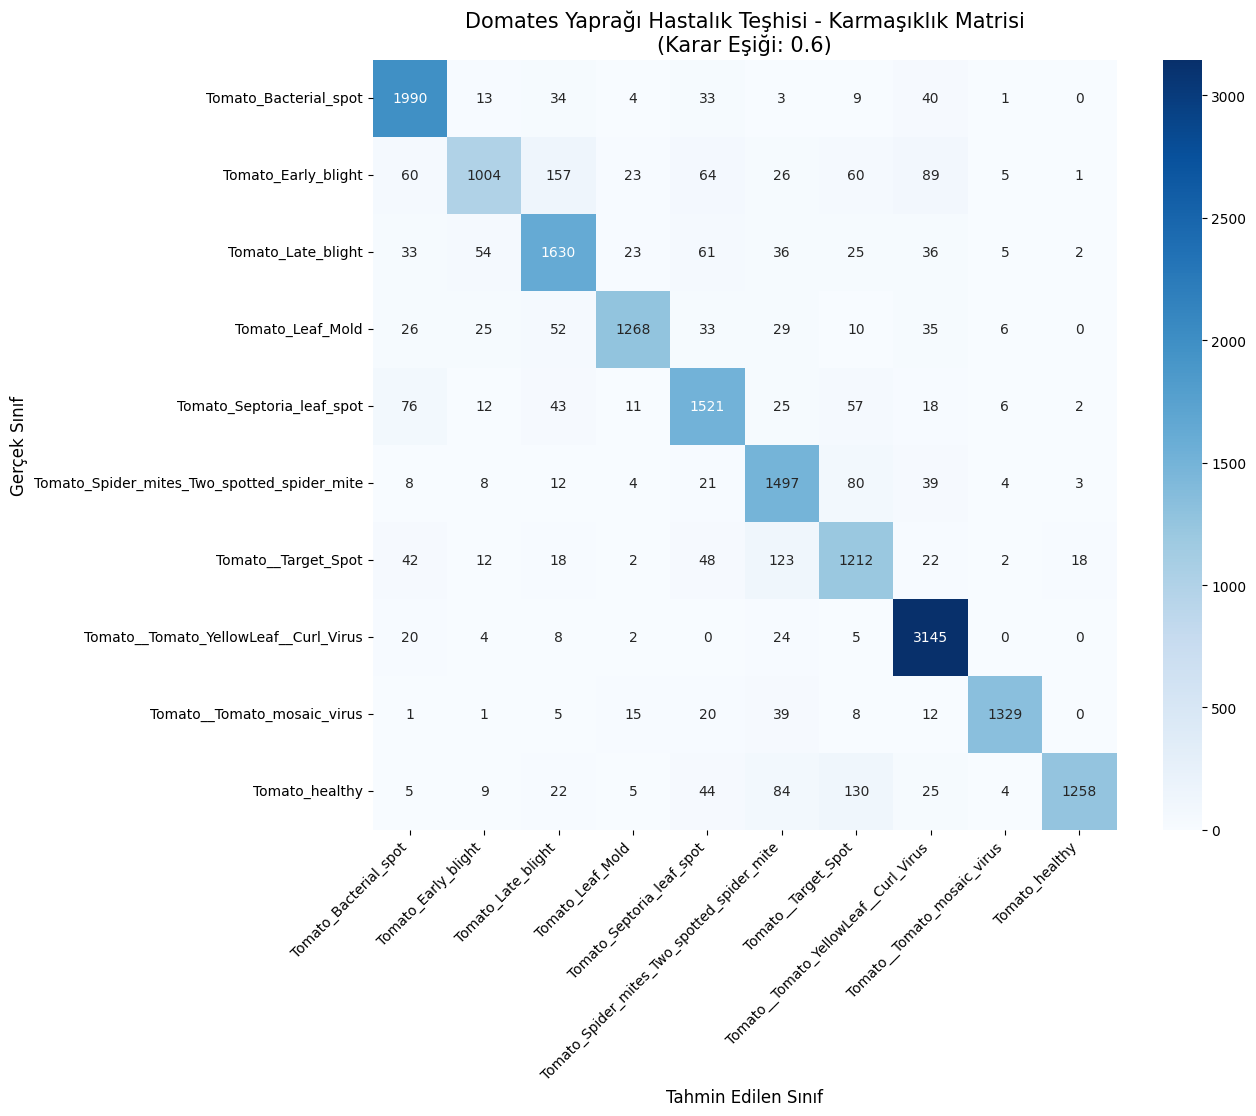

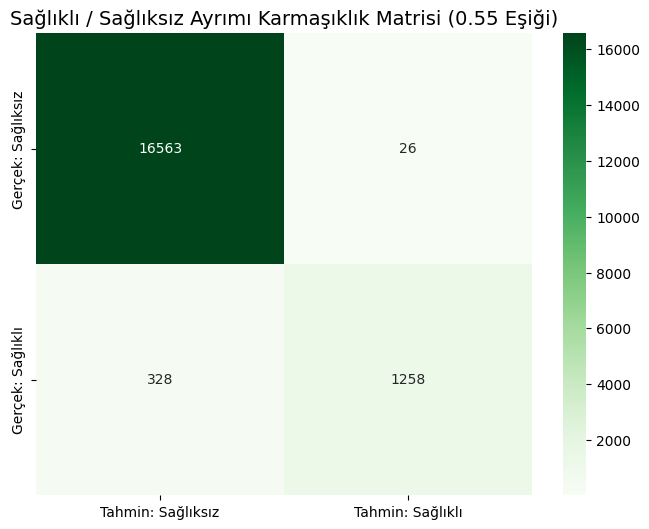

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_labels, y_pred_ensemble)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_map.values(),
            yticklabels=label_map.values())

plt.title(f'Domates Yaprağı Hastalık Teşhisi - Karmaşıklık Matrisi\n(Karar Eşiği: 0.6)', fontsize=15)
plt.ylabel('Gerçek Sınıf', fontsize=12)
plt.xlabel('Tahmin Edilen Sınıf', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.show()

healthy_idx = 9
y_true_bin = (y_labels == healthy_idx).astype(int)
y_pred_bin = (y_pred_ensemble == healthy_idx).astype(int)

cm_bin = confusion_matrix(y_true_bin, y_pred_bin)

plt.figure(figsize=(8, 6))
group_names = ['Gerçek: Sağlıksız\n(Hastalık)', 'Gerçek: Sağlıklı']
sns.heatmap(cm_bin, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Tahmin: Sağlıksız', 'Tahmin: Sağlıklı'],
            yticklabels=['Gerçek: Sağlıksız', 'Gerçek: Sağlıklı'])

plt.title('Sağlıklı / Sağlıksız Ayrımı Karmaşıklık Matrisi (0.55 Eşiği)', fontsize=14)
plt.show()


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score


results = {
    "Modelo": [
        "Stream A: FV + HOG  →  LinearSVC (Yapısal)",
        "Stream B: LBP       →  LightGBM (Dokusal)",
        "Stream C: LCS       →  k-NN (Renksel)",
        "Hibrit Füzyon (A+B+C) — Karar Katmanı",
    ],
    "Accuracy": [
        accuracy_score(y_labels, y_pred_A),
        accuracy_score(y_labels, y_pred_B),
        accuracy_score(y_labels, y_pred_C),
        accuracy_score(y_labels, y_pred_ensemble),
    ],
    "F1-Macro": [
        f1_score(y_labels, y_pred_A, average='macro', zero_division=0),
        f1_score(y_labels, y_pred_B, average='macro', zero_division=0),
        f1_score(y_labels, y_pred_C, average='macro', zero_division=0),
        f1_score(y_labels, y_pred_ensemble, average='macro', zero_division=0),
    ],
}

df_abl = pd.DataFrame(results)
df_abl["Accuracy"] = df_abl["Accuracy"].map("{:.4f}".format)
df_abl["F1-Macro"] = df_abl["F1-Macro"].map("{:.4f}".format)

print("\n" + "═"*65)
print("   ABLATION STUDY: SİSTEM BİLEŞENLERİNİN KATKI ANALİZİ")
print("═"*65)
print(df_abl.to_string(index=False))

acc_streams = [float(df_abl.iloc[i]["Accuracy"]) for i in range(3)]
acc_ens     = float(df_abl.iloc[3]["Accuracy"])
best_stream = max(acc_streams)
gain_pp     = (acc_ens - best_stream) * 100

print(f"\nEn İyi Tekil Akış Başarısı  : {best_stream:.4f}")
print(f"Füzyon Kazancı (Sinerji)    : +{gain_pp:.2f} puan")
print(f"Durum                       : {'✓ BAŞARILI: Hibrit yapı sinerji yaratıyor.' if gain_pp >= 2 else '⚠ UYARI: Kazanç düşük.'}")
print("═"*65)



═════════════════════════════════════════════════════════════════
   ABLATION STUDY: SİSTEM BİLEŞENLERİNİN KATKI ANALİZİ
═════════════════════════════════════════════════════════════════
                                    Modelo Accuracy F1-Macro
Stream A: FV + HOG  →  LinearSVC (Yapısal)   0.8363   0.8246
 Stream B: LBP       →  LightGBM (Dokusal)   0.7186   0.7039
     Stream C: LCS       →  k-NN (Renksel)   0.6909   0.6782
     Hibrit Füzyon (A+B+C) — Karar Katmanı   0.8723   0.8639

En İyi Tekil Akış Başarısı  : 0.8363
Füzyon Kazancı (Sinerji)    : +3.60 puan
Durum                       : ✓ BAŞARILI: Hibrit yapı sinerji yaratıyor.
═════════════════════════════════════════════════════════════════


After running `knJSf1GjjCc2` and then `i1L-Pp_WgvhC`, the ablation study should now execute successfully, providing insights into the contribution of each model stream to the overall ensemble performance.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
import numpy as np


X_meta = np.hstack([P_A_all, P_B_all, P_C_all])
y_meta = y_labels

X_meta_train, X_meta_test, y_meta_train, y_meta_test = train_test_split(
    X_meta, y_meta, test_size=0.2, stratify=y_meta, random_state=42
)

def build_improved_meta_model(input_dim, num_classes):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),

        layers.Dense(512, kernel_regularizer=regularizers.l2(1e-4)),
        layers.Activation('swish'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),

        layers.Dense(256, kernel_regularizer=regularizers.l2(1e-4)),
        layers.Activation('swish'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),

        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

meta_nn = build_improved_meta_model(X_meta.shape[1], num_classes)

callbacks_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=8, min_lr=1e-6, verbose=1)
]

print("\n[INFO] İyileştirilmiş Derin Stacking Eğitimi Başlıyor...")
history = meta_nn.fit(
    X_meta_train, y_meta_train,
    validation_data=(X_meta_test, y_meta_test),
    epochs=200,
    batch_size=32,
    callbacks=callbacks_list,
    verbose=1
)

y_final_probs = meta_nn.predict(X_meta_test)
healthy_id = 9
y_final_pred_opt = []

for probs in y_final_probs:
    if probs[healthy_id] > 0.55:
        y_final_pred_opt.append(healthy_id)
    else:
        temp_probs = probs.copy()
        temp_probs[healthy_id] = 0
        y_final_pred_opt.append(np.argmax(temp_probs))

y_final_pred_opt = np.array(y_final_pred_opt)

print("\n" + "="*60)
print("İYLEŞTİRİLMİŞ DEEP STACKING FÜZYON SONUÇLARI")
print("="*60)
print(f"Final Accuracy: %{accuracy_score(y_meta_test, y_final_pred_opt)*100:.2f}")
print("-" * 60)
print(classification_report(y_meta_test, y_final_pred_opt, digits=4))



[INFO] İyileştirilmiş Derin Stacking Eğitimi Başlıyor...
Epoch 1/200
455/455 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8700 - loss: 0.4794 - val_accuracy: 0.8908 - val_loss: 0.4780 - learning_rate: 0.0010
Epoch 2/200
455/455 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8858 - loss: 0.4155 - val_accuracy: 0.9059 - val_loss: 0.3316 - learning_rate: 0.0010
Epoch 3/200
455/455 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8883 - loss: 0.3996 - val_accuracy: 0.9045 - val_loss: 0.3348 - learning_rate: 0.0010
Epoch 4/200
455/455 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8915 - loss: 0.3889 - val_accuracy: 0.9070 - val_loss: 0.3253 - learning_rate: 0.0010
Epoch 5/200
455/455 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8925 - loss: 0.3823 - val_accuracy: 0.9067 - val_loss: 0.3282 - learning_rate: 0.0010
Epoch 6/200
455/455 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8944 - loss: 0.3780 - val_accuracy: 0.9010 - val_loss: 0.3355 - learning_rate: 0.0010
Epoch 7/200
455/455 ━━


   DEEP STACKING (MLP) SONRASI: SAĞLIKLI VS SAĞLIKSIZ
              precision    recall  f1-score   support

    Sağlıklı     0.9306    0.9306    0.9306       317
   Sağlıksız     0.9934    0.9934    0.9934      3318

    accuracy                         0.9879      3635
   macro avg     0.9620    0.9620    0.9620      3635
weighted avg     0.9879    0.9879    0.9879      3635



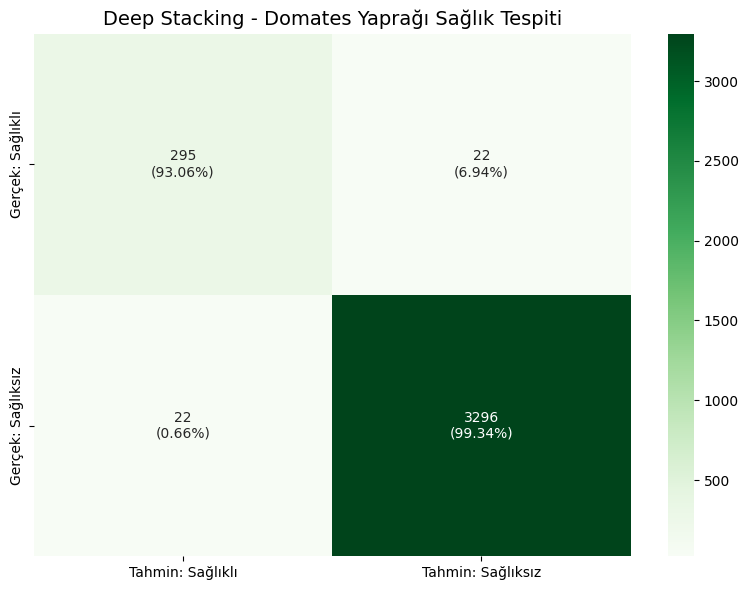


MLP Sonrası Genel Binary Doğruluk (Accuracy): %98.7895


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

healthy_id = None
for idx, name in contract['label_map'].items():
    if "healthy" in str(name).lower():
        healthy_id = int(idx)
        break

if healthy_id is None:
    raise ValueError("HATA: 'healthy' etiketli sınıf bulunamadı!")

y_true_binary = np.array([0 if y == healthy_id else 1 for y in y_meta_test])
y_pred_binary = np.array([0 if y == healthy_id else 1 for y in y_final_pred_opt])

print("\n" + "="*60)
print("   DEEP STACKING (MLP) SONRASI: SAĞLIKLI VS SAĞLIKSIZ")
print("="*60)
print(classification_report(y_true_binary, y_pred_binary,
                            target_names=['Sağlıklı', 'Sağlıksız'],
                            digits=4))

cm = confusion_matrix(y_true_binary, y_pred_binary)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(8, 6))
labels = (np.array(["{0:d}\n({1:.2%})".format(count, percent)
          for count, percent in zip(cm.flatten(), cm_percent.flatten())])).reshape(2,2)

sns.heatmap(cm, annot=labels, fmt="", cmap='Greens',                                                         
            xticklabels=['Tahmin: Sağlıklı', 'Tahmin: Sağlıksız'],
            yticklabels=['Gerçek: Sağlıklı', 'Gerçek: Sağlıksız'])

plt.title('Deep Stacking - Domates Yaprağı Sağlık Tespiti', fontsize=14)
plt.tight_layout()
plt.show()

acc = accuracy_score(y_true_binary, y_pred_binary)
print(f"\nMLP Sonrası Genel Binary Doğruluk (Accuracy): %{acc*100:.4f}")


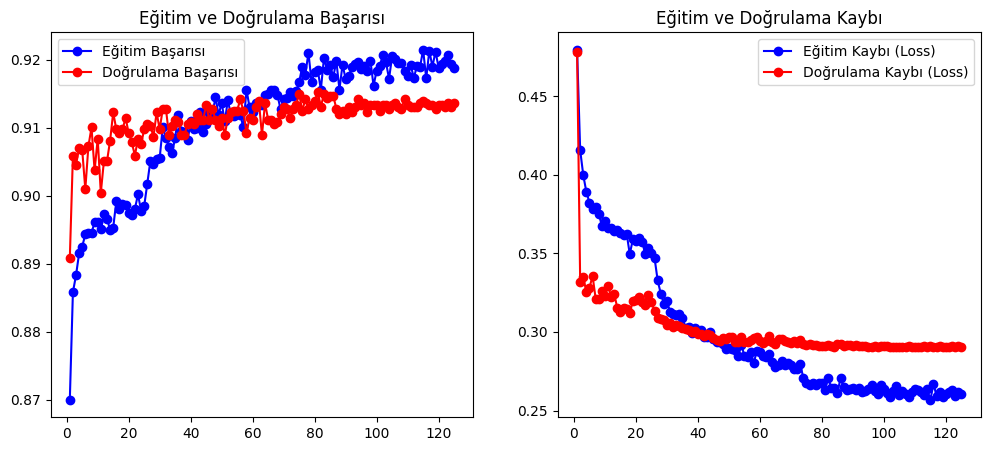

In [ ]:
import matplotlib.pyplot as plt

def plot_learning_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Eğitim Başarısı')
    plt.plot(epochs, val_acc, 'ro-', label='Doğrulama Başarısı')
    plt.title('Eğitim ve Doğrulama Başarısı')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Eğitim Kaybı (Loss)')
    plt.plot(epochs, val_loss, 'ro-', label='Doğrulama Kaybı (Loss)')
    plt.title('Eğitim ve Doğrulama Kaybı')
    plt.legend()

    plt.show()

plot_learning_history(history)


In [ ]:
import time

def measure_inference_speed(indices_to_test, n_trials=100):
    durations = []

    print(f"{n_trials} örnek üzerinde hız testi yapılıyor...")

    for i in range(min(n_trials, len(indices_to_test))):
        start_time = time.time()

        rgb, gray, lab = load_and_preprocess(paths[i])
        mask, _, _, _ = build_final_mask(gray, lab)
        mask_bin = (mask > 0).astype(np.uint8)

        f_lbp = extract_lbp_multiscale(rgb, mask_bin)
        f_hog = extract_hog_pyramidal(rgb, mask_bin)
        f_lcs = extract_lcs(rgb, mask_bin)
        desc_fv = extract_dense_sift_root(paths[i], mask_paths[i])
        f_fv = compute_fisher_vector(desc_fv, pca, gmm)

        s_a = np.hstack([f_fv.reshape(1,-1), f_hog.reshape(1,-1)])
        s_b = f_lbp.reshape(1,-1)
        s_c = f_lcs.reshape(1,-1)

        p_a = _clf_A.predict_proba(s_a)
        p_b = _clf_B.predict_proba(s_b)
        p_c = _clf_C.predict_proba(s_c)

        x_meta_sample = np.hstack([p_a, p_b, p_c])
        final_pred = meta_nn.predict(x_meta_sample, verbose=0)

        end_time = time.time()
        durations.append((end_time - start_time) * 1000)

    avg_latency = np.mean(durations)
    std_latency = np.std(durations)
    fps = 1000 / avg_latency

    print("\n" + "="*50)
    print("HIZ VE VERİMLİLİK ANALİZİ")
    print("="*50)
    print(f"Ortalama İşlem Süresi : {avg_latency:.2f} ms / görüntü")
    print(f"Standart Sapma         : {std_latency:.2f} ms")
    print(f"Tespit Hızı (FPS)      : {fps:.2f} kare/saniye")
    print("="*50)

measure_inference_speed(range(len(paths)), n_trials=100)


100 örnek üzerinde hız testi yapılıyor...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut


HIZ VE VERİMLİLİK ANALİZİ
Ortalama İşlem Süresi : 404.06 ms / görüntü
Standart Sapma         : 94.41 ms
Tespit Hızı (FPS)      : 2.47 kare/saniye


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


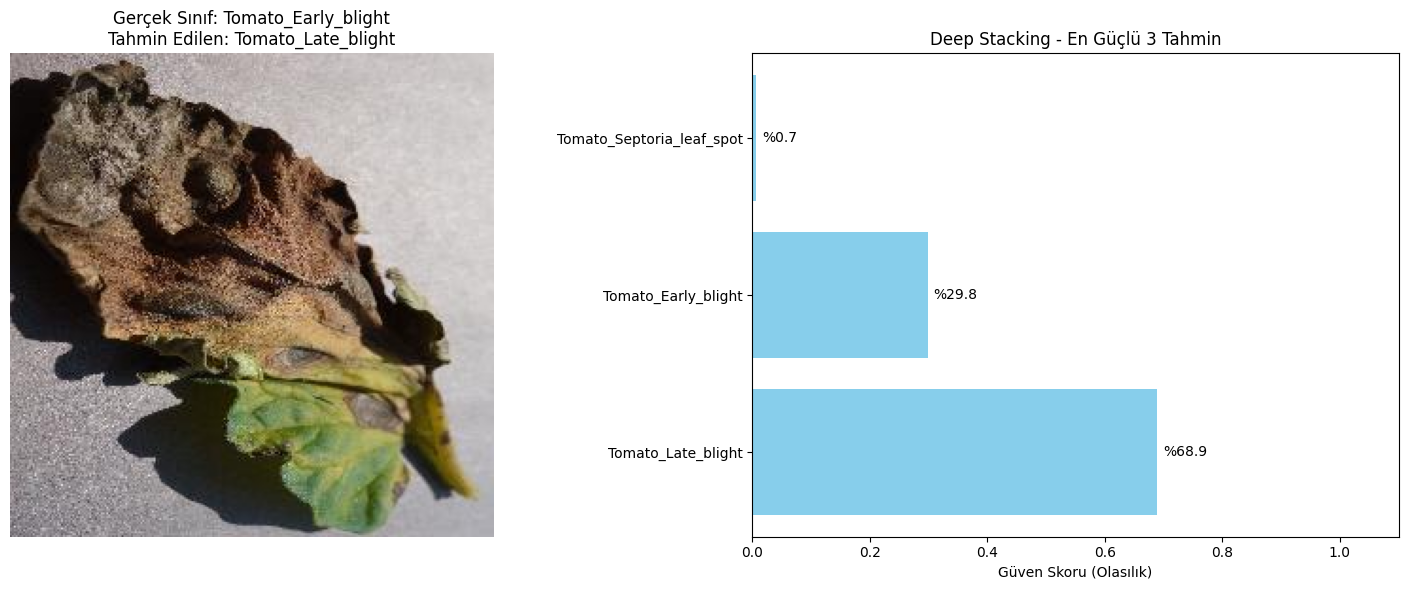


--- Uzman Model Kararları ---
Stream A (Yapısal - SVM)  : Tomato_Early_blight (Güven: %55.8)
Stream B (Dokusal - LGBM) : Tomato_Late_blight (Güven: %76.0)
Stream C (Renksel - kNN)  : Tomato_Late_blight (Güven: %73.7)
FINAL META-KARAR          : Tomato_Late_blight


In [ ]:
import matplotlib.pyplot as plt
import cv2
import random

def predict_and_visualize(sample_idx=None):
    if sample_idx is None:
        sample_idx = random.randint(0, len(paths)-1)

    img_path = paths[sample_idx]
    true_label = y_labels[sample_idx]

    p_a = P_A_all[sample_idx].reshape(1, -1)
    p_b = P_B_all[sample_idx].reshape(1, -1)
    p_c = P_C_all[sample_idx].reshape(1, -1)

    x_meta_input = np.hstack([p_a, p_b, p_c])
    final_probs = meta_nn.predict(x_meta_input, verbose=0)[0]
    final_pred = np.argmax(final_probs)

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(15, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title(f"Gerçek Sınıf: {label_map[true_label]}\nTahmin Edilen: {label_map[final_pred]}")
    plt.axis('off')

    top_indices = final_probs.argsort()[-3:][::-1]
    top_values = final_probs[top_indices]
    top_labels = [label_map[i] for i in top_indices]

    plt.subplot(1, 2, 2)
    bars = plt.barh(top_labels, top_values, color='skyblue')
    plt.xlabel('Güven Skoru (Olasılık)')
    plt.title('Deep Stacking - En Güçlü 3 Tahmin')
    plt.xlim(0, 1.1)

    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.01, bar.get_y() + bar.get_height()/2,
                 f'%{width*100:.1f}', va='center')

    plt.tight_layout()
    plt.show()

    print(f"\n--- Uzman Model Kararları ---")
    print(f"Stream A (Yapısal - SVM)  : {label_map[np.argmax(p_a)]} (Güven: %{np.max(p_a)*100:.1f})")
    print(f"Stream B (Dokusal - LGBM) : {label_map[np.argmax(p_b)]} (Güven: %{np.max(p_b)*100:.1f})")
    print(f"Stream C (Renksel - kNN)  : {label_map[np.argmax(p_c)]} (Güven: %{np.max(p_c)*100:.1f})")
    print(f"FINAL META-KARAR          : {label_map[final_pred]}")

predict_and_visualize()


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


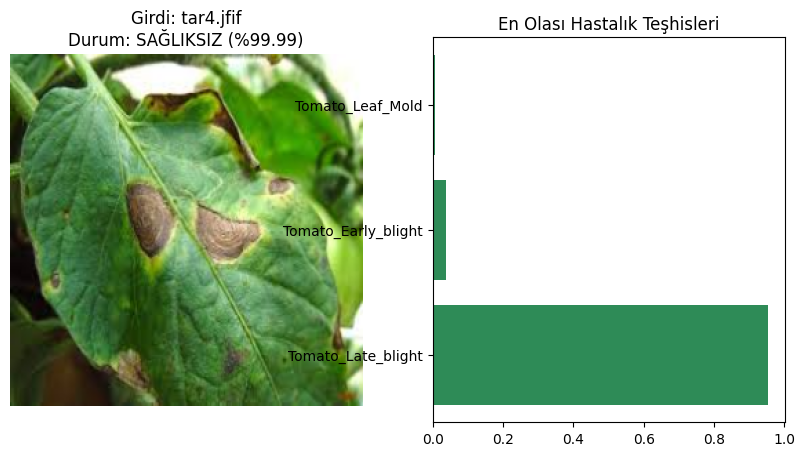


[DETAYLI KARAR]: Tomato_Late_blight


In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def detect_health_status(final_probs, label_map):
    """
    Sınıflandırma olasılıklarını kullanarak sağlıklı/sağlıksız durumunu belirler.
    """
    healthy_id = -1
    for idx, name in label_map.items():
        if "healthy" in str(name).lower():
            healthy_id = int(idx)
            break

    if healthy_id == -1:
        return "Bilinmiyor", 0.0

    prob_healthy = final_probs[healthy_id]
    prob_unhealthy = 1.0 - prob_healthy

    status = "SAĞLIKLI" if prob_healthy > 0.6 else "SAĞLIKSIZ"
    confidence = prob_healthy if status == "SAĞLIKLI" else prob_unhealthy

    return status, confidence

image_path = "tar4.jfif"

try:
    rgb, gray, lab = load_and_preprocess(image_path)
    mask, channel, r_L, r_C = build_final_mask(gray, lab)
    mask_bin = (mask > 0).astype(np.uint8)

    f_lbp = extract_lbp_multiscale(rgb, mask_bin)
    f_hog = extract_hog_pyramidal(rgb, mask_bin)
    f_lcs = extract_lcs(rgb, mask_bin)

    desc_fv = extract_dense_sift_root(image_path, "gecici_maske.npy")
    np.save("gecici_maske.npy", mask)

    if desc_fv is not None and len(desc_fv) > 0:
        f_fv = compute_fisher_vector(desc_fv, pca, gmm)
    else:
        f_fv = np.zeros(4096, dtype=np.float32)

    s_a = np.hstack([f_fv.reshape(1,-1), f_hog.reshape(1,-1)])
    s_b = f_lbp.reshape(1,-1)
    s_c = f_lcs.reshape(1,-1)

    p_a = _clf_A.predict_proba(s_a)
    p_b = _clf_B.predict_proba(s_b)
    p_c = _clf_C.predict_proba(s_c)

    x_meta_input = np.hstack([p_a, p_b, p_c])
    final_probs = meta_nn.predict(x_meta_input, verbose=0)[0]

    status, health_conf = detect_health_status(final_probs, label_map)

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(rgb)
    plt.title(f"Girdi: {image_path}\nDurum: {status} (%{health_conf*100:.2f})")
    plt.axis('off')

    top3_idx = final_probs.argsort()[-3:][::-1]
    plt.subplot(1, 2, 2)
    plt.barh([label_map[i] for i in top3_idx], final_probs[top3_idx], color='seagreen')
    plt.title("En Olası Hastalık Teşhisleri")
    plt.show()

    print(f"\n[DETAYLI KARAR]: {label_map[np.argmax(final_probs)]}")

except Exception as e:
    print(f"Bir hata oluştu: {e}")


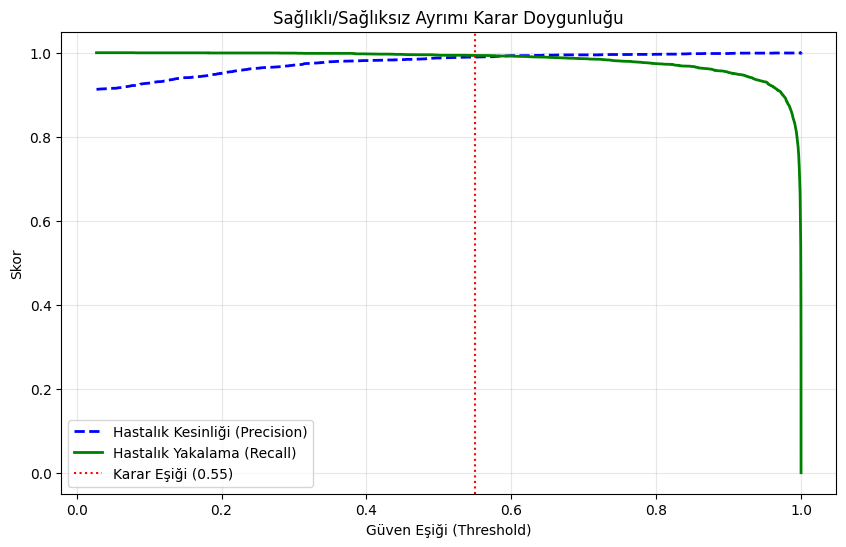

In [ ]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

prob_healthy = X_meta_test[:, healthy_id]
y_true_binary = (y_meta_test != healthy_id).astype(int)

precision, recall, thresholds = precision_recall_curve(y_true_binary, 1 - prob_healthy)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision[:-1], 'b--', label='Hastalık Kesinliği (Precision)', lw=2)
plt.plot(thresholds, recall[:-1], 'g-', label='Hastalık Yakalama (Recall)', lw=2)

plt.axvline(x=0.55, color='red', linestyle=':', label='Karar Eşiği (0.55)')

plt.title('Sağlıklı/Sağlıksız Ayrımı Karar Doygunluğu')
plt.xlabel('Güven Eşiği (Threshold)')
plt.ylabel('Skor')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:
import time
import numpy as np

def measure_full_inference(image_path):
    """
    Bir görselin ön işlemeden nihai karara kadar geçen toplam süresini ölçer.
    """
    start_time = time.time()

    try:
        rgb, gray, lab = load_and_preprocess(image_path)
        mask, channel, _, _ = build_final_mask(gray, lab)
        mask_bin = (mask > 0).astype(np.uint8)

        f_lbp = extract_lbp_multiscale(rgb, mask_bin)
        f_hog = extract_hog_pyramidal(rgb, mask_bin)
        f_lcs = extract_lcs(rgb, mask_bin)

        np.save("temp_mask.npy", mask)
        desc_fv = extract_dense_sift_root(image_path, "temp_mask.npy")
        if desc_fv is not None and len(desc_fv) > 0:
            f_fv = compute_fisher_vector(desc_fv, pca, gmm)
        else:
            f_fv = np.zeros(4096, dtype=np.float32)

        s_a = np.hstack([f_fv.reshape(1,-1), f_hog.reshape(1,-1)])
        s_b = f_lbp.reshape(1,-1)
        s_c = f_lcs.reshape(1,-1)

        p_a = _clf_A.predict_proba(s_a)
        p_b = _clf_B.predict_proba(s_b)
        p_c = _clf_C.predict_proba(s_c)

        x_meta_input = np.hstack([p_a, p_b, p_c])
        final_probs = meta_nn.predict(x_meta_input, verbose=0)[0]

        status, confidence = detect_health_status(final_probs, label_map)

        end_time = time.time()
        total_duration = end_time - start_time

        print("-" * 40)
        print(f"GÖRSEL: {image_path}")
        print(f"TOPLAM SÜRE: {total_duration:.4f} saniye")
        print(f"HIZ: {1/total_duration:.2f} FPS (Görsel/Saniye)")
        print(f"KARAR: {status} (%{confidence*100:.2f})")
        print("-" * 40)

        return total_duration

    except Exception as e:
        print(f"Hata oluştu: {e}")
        return None

measure_full_inference("tar.jfif")


----------------------------------------
GÖRSEL: tar.jfif
TOPLAM SÜRE: 0.3455 saniye
HIZ: 2.89 FPS (Görsel/Saniye)
KARAR: SAĞLIKSIZ (%100.00)
----------------------------------------


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


0.3455018997192383

In [ ]:
import numpy as np
import pandas as pd

def final_error_analysis(X_meta_test, y_meta_test, meta_nn, label_map):
    y_probs = meta_nn.predict(X_meta_test, verbose=0)
    y_pred = np.argmax(y_probs, axis=1)

    try:
        healthy_idx = [k for k, v in label_map.items() if 'healthy' in str(v).lower()][0]
    except IndexError:
        print("Sağlıklı sınıfı bulunamadı, varsayılan ID (9) deneniyor...")
        healthy_idx = 9

    error_mask = (y_meta_test == healthy_idx) & (y_pred != healthy_idx)

    if np.sum(error_mask) == 0:
        return "Analiz edilecek hata (False Positive) bulunamadı. Model bu sınıfta kusursuz."

    X_err = X_meta_test[error_mask]
    y_pred_err = y_pred[error_mask]

    results = []
    for i in range(len(X_err)):
        p_a = X_err[i, 0:10]
        p_b = X_err[i, 10:20]
        p_c = X_err[i, 20:30]

        results.append({
            "Örnek": i,
            "Gerçek": label_map[healthy_idx],
            "Meta Karar": label_map[y_pred_err[i]],
            "A (Yapı)": label_map[np.argmax(p_a)],
            "B (Doku)": label_map[np.argmax(p_b)],
            "C (Renk)": label_map[np.argmax(p_c)]
        })

    return pd.DataFrame(results)

analiz_df = final_error_analysis(X_meta_test, y_meta_test, meta_nn, label_map)
analiz_df


,Örnek,Gerçek,Meta Karar,A (Yapı),B (Doku),C (Renk)
0,0,Tomato_healthy,Tomato__Target_Spot,Tomato__Target_Spot,Tomato__Target_Spot,Tomato_healthy
1,1,Tomato_healthy,Tomato_Septoria_leaf_spot,Tomato_healthy,Tomato_Septoria_leaf_spot,Tomato__Tomato_YellowLeaf__Curl_Virus
2,2,Tomato_healthy,Tomato__Target_Spot,Tomato_Early_blight,Tomato__Target_Spot,Tomato__Tomato_YellowLeaf__Curl_Virus
3,3,Tomato_healthy,Tomato_Septoria_leaf_spot,Tomato_Septoria_leaf_spot,Tomato__Target_Spot,Tomato_healthy
4,4,Tomato_healthy,Tomato_Septoria_leaf_spot,Tomato_healthy,Tomato_Septoria_leaf_spot,Tomato__Tomato_YellowLeaf__Curl_Virus
5,5,Tomato_healthy,Tomato__Target_Spot,Tomato_healthy,Tomato_Septoria_leaf_spot,Tomato__Target_Spot
6,6,Tomato_healthy,Tomato__Target_Spot,Tomato__Target_Spot,Tomato_healthy,Tomato__Target_Spot
7,7,Tomato_healthy,Tomato_Septoria_leaf_spot,Tomato_healthy,Tomato__Target_Spot,Tomato__Tomato_YellowLeaf__Curl_Virus
8,8,Tomato_healthy,Tomato_Septoria_leaf_spot,Tomato_Septoria_leaf_spot,Tomato_healthy,Tomato_Leaf_Mold
9,9,Tomato_healthy,Tomato__Target_Spot,Tomato__Target_Spot,Tomato_healthy,Tomato_healthy
